## Project Motivation
Standard GNN classifiers achieve high global accuracy, but minority-class recall can collapse where isotropic message passing averages a node's features with neighbours that mostly belong to *other* classes (a heterophilous neighbourhood), smearing its signal into majority centroids. We evaluate whether an adaptive, homophily-gated architecture preserves such decision boundaries.

**How our hypothesis changed (measured, not assumed).** We began by assuming that *rare* cells (e.g. CD34+, <1%) sit at heterophilous boundaries. Measuring edge homophily on the actual kNN graph (global 0.412, 65,578 cells) refuted the rarity framing: the most heterophilous classes are the *abundant* T-cell subtypes (Naive T, Memory, Treg, CD8+ Cytotoxic, all < 0.3), while distinct lineages (NK, Monocyte, B) are comparatively coherent. The heterophily is therefore largely a **label-granularity effect** — closely-related subtypes share one expression manifold — strongest in the T-cell family; extreme scarcity only compounds it for CD4+ T Helper2 (91 cells, homophily ~0.001). The gated model is thus motivated by a *measured*, pervasive property, with the mechanism identified as subtype confusion rather than rarity.


## Project Description
We formulate single-cell annotation as transductive semi-supervised node classification on Zheng 68k PBMC (N68,000, 11 discrete classes) across label-scarcity splits (1%, 2%, 5%, 10%, 20%, or 5–20 labeled cells/class). Severe class imbalance (abundant T cells to <1% CD34+ cells) makes this a natural test of minority-class smoothing under graph message passing. 

## Part 1 — Data Ingestion and Review
*Contribution: establishes trust in the raw data and identifies the label column and feature matrix — we interrogate `X`/obs/var rather than assume what the numbers are.*

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
from IPython.display import display

import inspect
from sklearn.manifold import LocallyLinearEmbedding, SpectralEmbedding, TSNE


sc.settings.verbosity = 2
sc.set_figure_params(dpi=90, facecolor="white")
sns.set_theme(style="whitegrid")
SEED = 42
DATA_PATH = Path("data/PBMC/pbmc68k.h5ad")
if not DATA_PATH.is_file(): 
    print("downloading file ")
    
    import scvelo as scv
    adata_source = scv.datasets.pbmc68k(file_path=str(DATA_PATH))
    del adata_source # standardise read format 
print("Input:", DATA_PATH.resolve(), f"({DATA_PATH.stat().st_size / 2**20:,.1f} MiB)")
adata = sc.read_h5ad(DATA_PATH)
print(adata)


downloading file 
try downloading from url
https://ndownloader.figshare.com/files/27686886
... this may take a while but only happens once
creating directory data/PBMC/ for saving data


100%|██████████| 118M/118M [00:01<00:00, 72.4MB/s] 


Input: /Users/yolandahp/Documents/NUS/Graph Machine Learning/Graph-ML/data/PBMC/pbmc68k.h5ad (118.0 MiB)
AnnData object with n_obs × n_vars = 65877 × 33939
    obs: 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    obsm: 'X_tsne'
    layers: 'spliced', 'unspliced'


| Item | Meaning | Role in your graph-versus-classifier study |
| --- | --- | --- |
| `adata.obs.index` | Cell barcodes, such as `AAACATACACCCAA` | Stable row identifiers. Use them to align predictions with cells. Keep them exactly as stored; adding or stripping `-1` without checking can cause mismatches. |
| `adata.obs["celltype"]` | A categorical annotation with **11 classes** and no missing values | The likely prediction target. Examine counts per class and split cells into train/test sets before evaluating either model. Do **not** feed this column into the classifier, PCA, or graph construction. |

In [2]:
# reivew obs
print(f"Number of barcodes {adata.obs.index.nunique()} \t ==> \t\t [Example]: { adata.obs.index[0]}") # 65877 barcodes 
print(f"Number of type {adata.obs.celltype.nunique()} \t\t ==> \t\t [Example]: { adata.obs.celltype[0]}") # 65877 barcodes 
display(adata.obs)


Number of barcodes 65877 	 ==> 		 [Example]: AAACATACACCCAA
Number of type 11 		 ==> 		 [Example]: CD8+ Cytotoxic T


,celltype
AAACATACACCCAA,CD8+ Cytotoxic T
AAACATACCCCTCA,CD8+/CD45RA+ Naive Cytotoxic
AAACATACCGGAGA,CD4+/CD45RO+ Memory
AAACATACTAACCG,CD19+ B
AAACATACTCTTCA,CD4+/CD25 T Reg
...,...
TTTGCATGAGCCTA,CD8+ Cytotoxic T
TTTGCATGCTAGCA,CD8+/CD45RA+ Naive Cytotoxic
TTTGCATGCTGCAA,CD8+ Cytotoxic T
TTTGCATGGCTCCT,CD8+ Cytotoxic T


| Item | Meaning | Why it matters |
| --- | --- | --- |
| `adata.var` | Gene names, such as `FAM138A` | These identify the 33,939 expression features. Keep the same selected genes, in the same order, for both models. |
| `Accession` | A distinct Ensembl-style gene identifier for each gene | Useful for unambiguous gene tracking, especially where names are similar. It is an identifier, not an expression value. |
| `Chromosome` | The chromosome or sequence listed for each gene | Useful for checking gene composition, including whether mitochondrial genes can be identified. Its 40 categories need inspection before interpretation. |
| `Start`, `End` | Genomic coordinates recorded for each gene | Describe gene locations. They do not give the cell’s expression level and should not automatically become model features. The genome assembly is not specified by this output. |
| `Strand` | `+` or `-` genomic strand | Describes gene orientation. It is relevant to gene annotation, but not a cell-type feature by itself. |

In [3]:
# reivew var
print(f"Gene Name {adata.var.index.nunique()} \t\t ==> \t [Example]: { adata.var.index[1]}") # 33939 Gene 
print(f"Ensembl identifier {adata.var.Accession.nunique()} \t\t ==> \t [Example]: { adata.var.Accession[0]}") # 33939 
print(f"Chromosone {adata.var.Chromosome.nunique()} \t\t ==> \t [Example]: { adata.var.Chromosome[0]}") # 40 chromosone types
print(f"Start,End Geometric Coordinate of gene \t\t ==> \t [Example]: { adata.var.Start[0], adata.var.End[0]  }") # Coordinates of gene 
print()
print(f"Strand {adata.var.Strand.nunique()} \t\t ==> \t \n[Example]: { adata.var.Strand.value_counts()}") # 40 chromosone types 


Gene Name 33939 		 ==> 	 [Example]: AL627309.1
Ensembl identifier 33939 		 ==> 	 [Example]: ENSG00000237613
Chromosone 40 		 ==> 	 [Example]: 1
Start,End Geometric Coordinate of gene 		 ==> 	 [Example]: (np.int64(34554), np.int64(36081))

Strand 2 		 ==> 	 
[Example]: Strand
+    17134
-    16805
Name: count, dtype: int64


In [4]:
display(adata.var)

,Accession,Chromosome,End,Start,Strand
Gene,,,,,
FAM138A,ENSG00000237613,1,36081,34554,-
AL627309.1,ENSG00000238009,1,133723,89295,-
AL627309.3,ENSG00000239945,1,91105,89551,-
AL627309.2,ENSG00000239906,1,140339,139790,-
OR4F29,ENSG00000284733,1,451697,450703,-
...,...,...,...,...,...
TTTY4B,ENSG00000235412,Y,24607025,24570202,+
BPY2B,ENSG00000183795,Y,24639207,24607560,+
DAZ4,ENSG00000205916,Y,24907040,24833843,+


| Item | What your output shows | Interpretation for this project |
| --- | --- | --- |
| `adaat.X` | A 65,877 × 33,939 `float32` matrix | The main expression matrix and potential common feature source. **`float32` does not establish whether these are raw counts, normalized counts, or log values.** Check before running the notebook’s count-based QC and normalization. |
| `adaat.layers["spliced"]` | A same-size `uint16` matrix | Counts assigned as spliced transcripts. Spliced, mature RNA abundance for one cell and one gene. Potentially useful for RNA-velocity analyses; its values and relationship to `X` need checking before using it as an expression feature source. |
| `adaat.layers["unspliced"]` | A same-size `uint16` matrix | Counts assigned as unspliced transcripts. Unspliced, precursor RNA abundance for one cell and one gene. The same caution applies. Do not assume `spliced + unspliced == X`. |
| `obsm["X_tsne"]` | Two coordinates per cell | An existing **visualization**, useful for looking at how annotated cells are arranged. It is not evidence that a neighbor graph is stored and should not be used as the shared expression features for the comparison. |

In [5]:
# reivew matrix (X and layers spliced/unspliced)
adata.obsm['X_tsne'].shape


print(f"Feature Matrx {adata.X.shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.X[:3, :3].toarray()}")
print('\n\n')


print(f"Spliced Matrx {adata.layers['spliced'].shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.layers['spliced'][:3, :3].toarray()}")
print('\n\n')


print(f"Unspliced Matrx {adata.layers['unspliced'].shape}\t\t ==> \t \n[Example | 1st 3 row n col]:\n {adata.layers['unspliced'][:3, :3].toarray()}")
print('\n\n')

print(f"obsm tsne size {adata.obsm['X_tsne'].shape} \t\t ==> \t \n[Example first 2 row]:\n{ adata.obsm['X_tsne'][:2, :]}") # tSNE coord of cell 



Feature Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]



Spliced Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]



Unspliced Matrx (65877, 33939)		 ==> 	 
[Example | 1st 3 row n col]:
 [[0 0 0]
 [0 0 0]
 [0 0 0]]



obsm tsne size (65877, 2) 		 ==> 	 
[Example first 2 row]:
[[  7.56553972   0.44137032]
 [  2.55262557 -25.78667227]]


In [6]:
# print("Shape (cells, genes):", adata.shape)
# print("X:", type(adata.X).__name__, adata.X.dtype)
# print("obs columns:", list(adata.obs.columns))
# print("var columns:", list(adata.var.columns))
# print("layers:", {k: (v.shape, str(v.dtype)) for k, v in adata.layers.items()})
# print("obsm:", {k: v.shape for k, v in adata.obsm.items()})
# print("Unique cell IDs:", adata.obs_names.is_unique, "duplicate count:", adata.obs_names.duplicated().sum())
# print("Unique gene IDs:", adata.var_names.is_unique, "duplicate count:", adata.var_names.duplicated().sum())
# display(adata.obs.head(), adata.var.head())
# display(pd.DataFrame({"cell_id": adata.obs_names[:10]}))


In [7]:
# matrix review 
def matrix_snapshot(matrix,  seed=SEED):
    """Small diagnostic sample; does not densify a cell-by-gene matrix."""
    rng = np.random.default_rng(seed)
    values = matrix.data if sp.issparse(matrix) else np.asarray(matrix).ravel()
    values = np.asarray(values)
    if values.size == 0:
        return dict(dtype=str(matrix.dtype), sampled=0, min=np.nan, max=np.nan,
                    nonnegative=True, integer_like=True, finite=True)
    return dict(dtype=str(matrix.dtype), 
                sampled=len(values),
                min=float(values.min()), max=float(values.max()), 
                matrix_nonnegative=bool(np.all(values >= 0)),
                integer_like=bool(np.allclose(values, np.rint(values), atol=1e-6, rtol=0)),
                percent_of_matrix_filled = str(round(len(values) / (matrix.shape[0] * matrix.shape[1]) * 100 , 4)) + '%'
                )

matrix_report = pd.DataFrame({name: matrix_snapshot(matrix) for name, matrix in
                              {"X": adata.X, **dict(adata.layers)}.items()}).T
display(matrix_report)


,dtype,sampled,min,max,matrix_nonnegative,integer_like,percent_of_matrix_filled
X,float32,7111339,1.0,47.0,True,True,0.3181%
spliced,uint16,7111339,1.0,47.0,True,True,0.3181%
unspliced,uint16,2532929,1.0,25.0,True,True,0.1133%


### Part 2 — Exploratory Review (metadata distributions)
*Contribution: surfaces the severe class imbalance (down to the 91-cell CD4+ T Helper2) that drives the per-class QC guardrail, the stratified split, and the macro-F1 / class-weighted-loss plan.*

Review metadata distributions without assuming any column is a verified label.

Mitochondrial gene detection relies on gene names stored in this file and may be unavailable for Ensembl-style IDs. Such missing metrics are explicitly skipped.

In [8]:
metadata_summary = pd.DataFrame({
    "dtype": adata.obs.dtypes.astype(str),
    "missing_n": adata.obs.isna().sum(),
    "unique_n": adata.obs.nunique(dropna=True),
}).sort_index()
display(metadata_summary)

for column in adata.obs.columns:
    print(f"\n{column}:")
    display(adata.obs[column].astype("string").value_counts(dropna=False).to_frame("cells"))


,dtype,missing_n,unique_n
celltype,category,0,11



celltype:


,cells
celltype,
CD8+ Cytotoxic T,19941
CD8+/CD45RA+ Naive Cytotoxic,16032
CD56+ NK,8440
CD4+/CD25 T Reg,5921
CD19+ B,5674
CD4+/CD45RO+ Memory,2945
CD14+ Monocyte,2749
Dendritic,2014
CD4+/CD45RA+/CD25- Naive T,1802


In [9]:
# qc.var["mt"]
# qc.var[qc.var['mt']]
adata.var[adata.var_names.str.startswith('MT-')]#.index.value_counts()

,Accession,Chromosome,End,Start,Strand
Gene,,,,,
MT-ND6,ENSG00000198695,MT,14673,14149,-
MT-ND1,ENSG00000198888,MT,4262,3307,+
MT-ND2,ENSG00000198763,MT,5511,4470,+
MT-CO1,ENSG00000198804,MT,7445,5904,+
MT-CO2,ENSG00000198712,MT,8269,7586,+
MT-ATP8,ENSG00000228253,MT,8572,8366,+
MT-ATP6,ENSG00000198899,MT,9207,8527,+
MT-CO3,ENSG00000198938,MT,9990,9207,+
MT-ND3,ENSG00000198840,MT,10404,10059,+


### Part 3 — Quality Control
*Contribution: removes technical artifacts without biasing against any cell type — the per-class guardrail makes "we didn't drop the minorities" a checked claim.*

Basic analysis of key data (total counts, genes by counts, mitochondrial %, ...).

In [10]:
qc = adata.copy()
# Preserve original expression in `adata`; all downstream changes are made to `qc` or `work`.
gene_symbols = pd.Series(qc.var_names.astype(str), index=qc.var_names)
qc.var["mt"] = gene_symbols.str.upper().str.startswith("MT-").to_numpy()

## Using mitochondrial as an example 
print("Mitochondrial genes recognized:", int(qc.var["mt"].sum()))
if not qc.var["mt"].any():
    warnings.warn("No MT- gene names found. Mitochondrial percentage cannot be interpreted from these identifiers.")

qc_vars = ["mt"] if qc.var["mt"].any() else []
sc.pp.calculate_qc_metrics(qc, qc_vars=qc_vars, percent_top=None, log1p=False, inplace=True)
# https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.calculate_qc_metrics.html

# Calculates a number of qc metrics for an AnnData object, see section Returns for specifics. 
# Largely based on calculateQCMetrics from scater [McCarthy et al., 2017]. Currently is most efficient on a sparse CSR or dense matrix.


## total count is number of count  (ie cell with 2  gene => 2 instance )
## n_gene_by_counts is number of cell with that gene (ie cell with 2 of the SAME gene => 1 cell instance)  

print('''
Table showing variation across cell 
ie: 1% value of n_genes_by_counts helps you see the low-detection tail; the 99% value of total_counts helps reveal unusually high-depth cells.
''')
qc_cols = ["total_counts", "n_genes_by_counts"] + (["pct_counts_mt"] if qc_vars else [])
display(qc.obs[qc_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

print('''
\nTable showing variation across genes. It shows whether many genes occur in very few cells and how unevenly total expression is distributed among genes. 
.T simply transposes each summary to make one metric appear per row
''')
display(qc.var[["n_cells_by_counts", "total_counts"]].describe(percentiles=[.01, .5, .99]).T)

# print("Zero-count cells:", int((qc.obs.total_counts == 0).sum()))
# print("Never-observed genes:", int((qc.var.n_cells_by_counts == 0).sum()))


Mitochondrial genes recognized: 13

Table showing variation across cell 
ie: 1% value of n_genes_by_counts helps you see the low-detection tail; the 99% value of total_counts helps reveal unusually high-depth cells.



,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
total_counts,65877.0,148.584961,33.414818,0.0,40.0,79.0,135.000000,155.000000,171.000000,190.000000,204.000000,244.000000
n_genes_by_counts,65877.0,107.948738,21.532068,0.0,36.0,65.0,98.000000,111.000000,122.000000,136.000000,146.000000,171.000000
pct_counts_mt,65876.0,2.177375,1.593788,0.0,0.0,0.0,1.129943,1.941748,2.994012,4.929577,6.802722,38.392857




Table showing variation across genes. It shows whether many genes occur in very few cells and how unevenly total expression is distributed among genes. 
.T simply transposes each summary to make one metric appear per row



,count,mean,std,min,1%,50%,99%,max
n_cells_by_counts,33939.0,209.532956,1932.852793,0.0,0.0,0.0,2861.78,60907.0
total_counts,33939.0,288.409515,3787.079834,0.0,0.0,0.0,3133.10,204668.0


In [11]:
# qc.obs

total_counts
n_genes_by_counts
pct_counts_mt


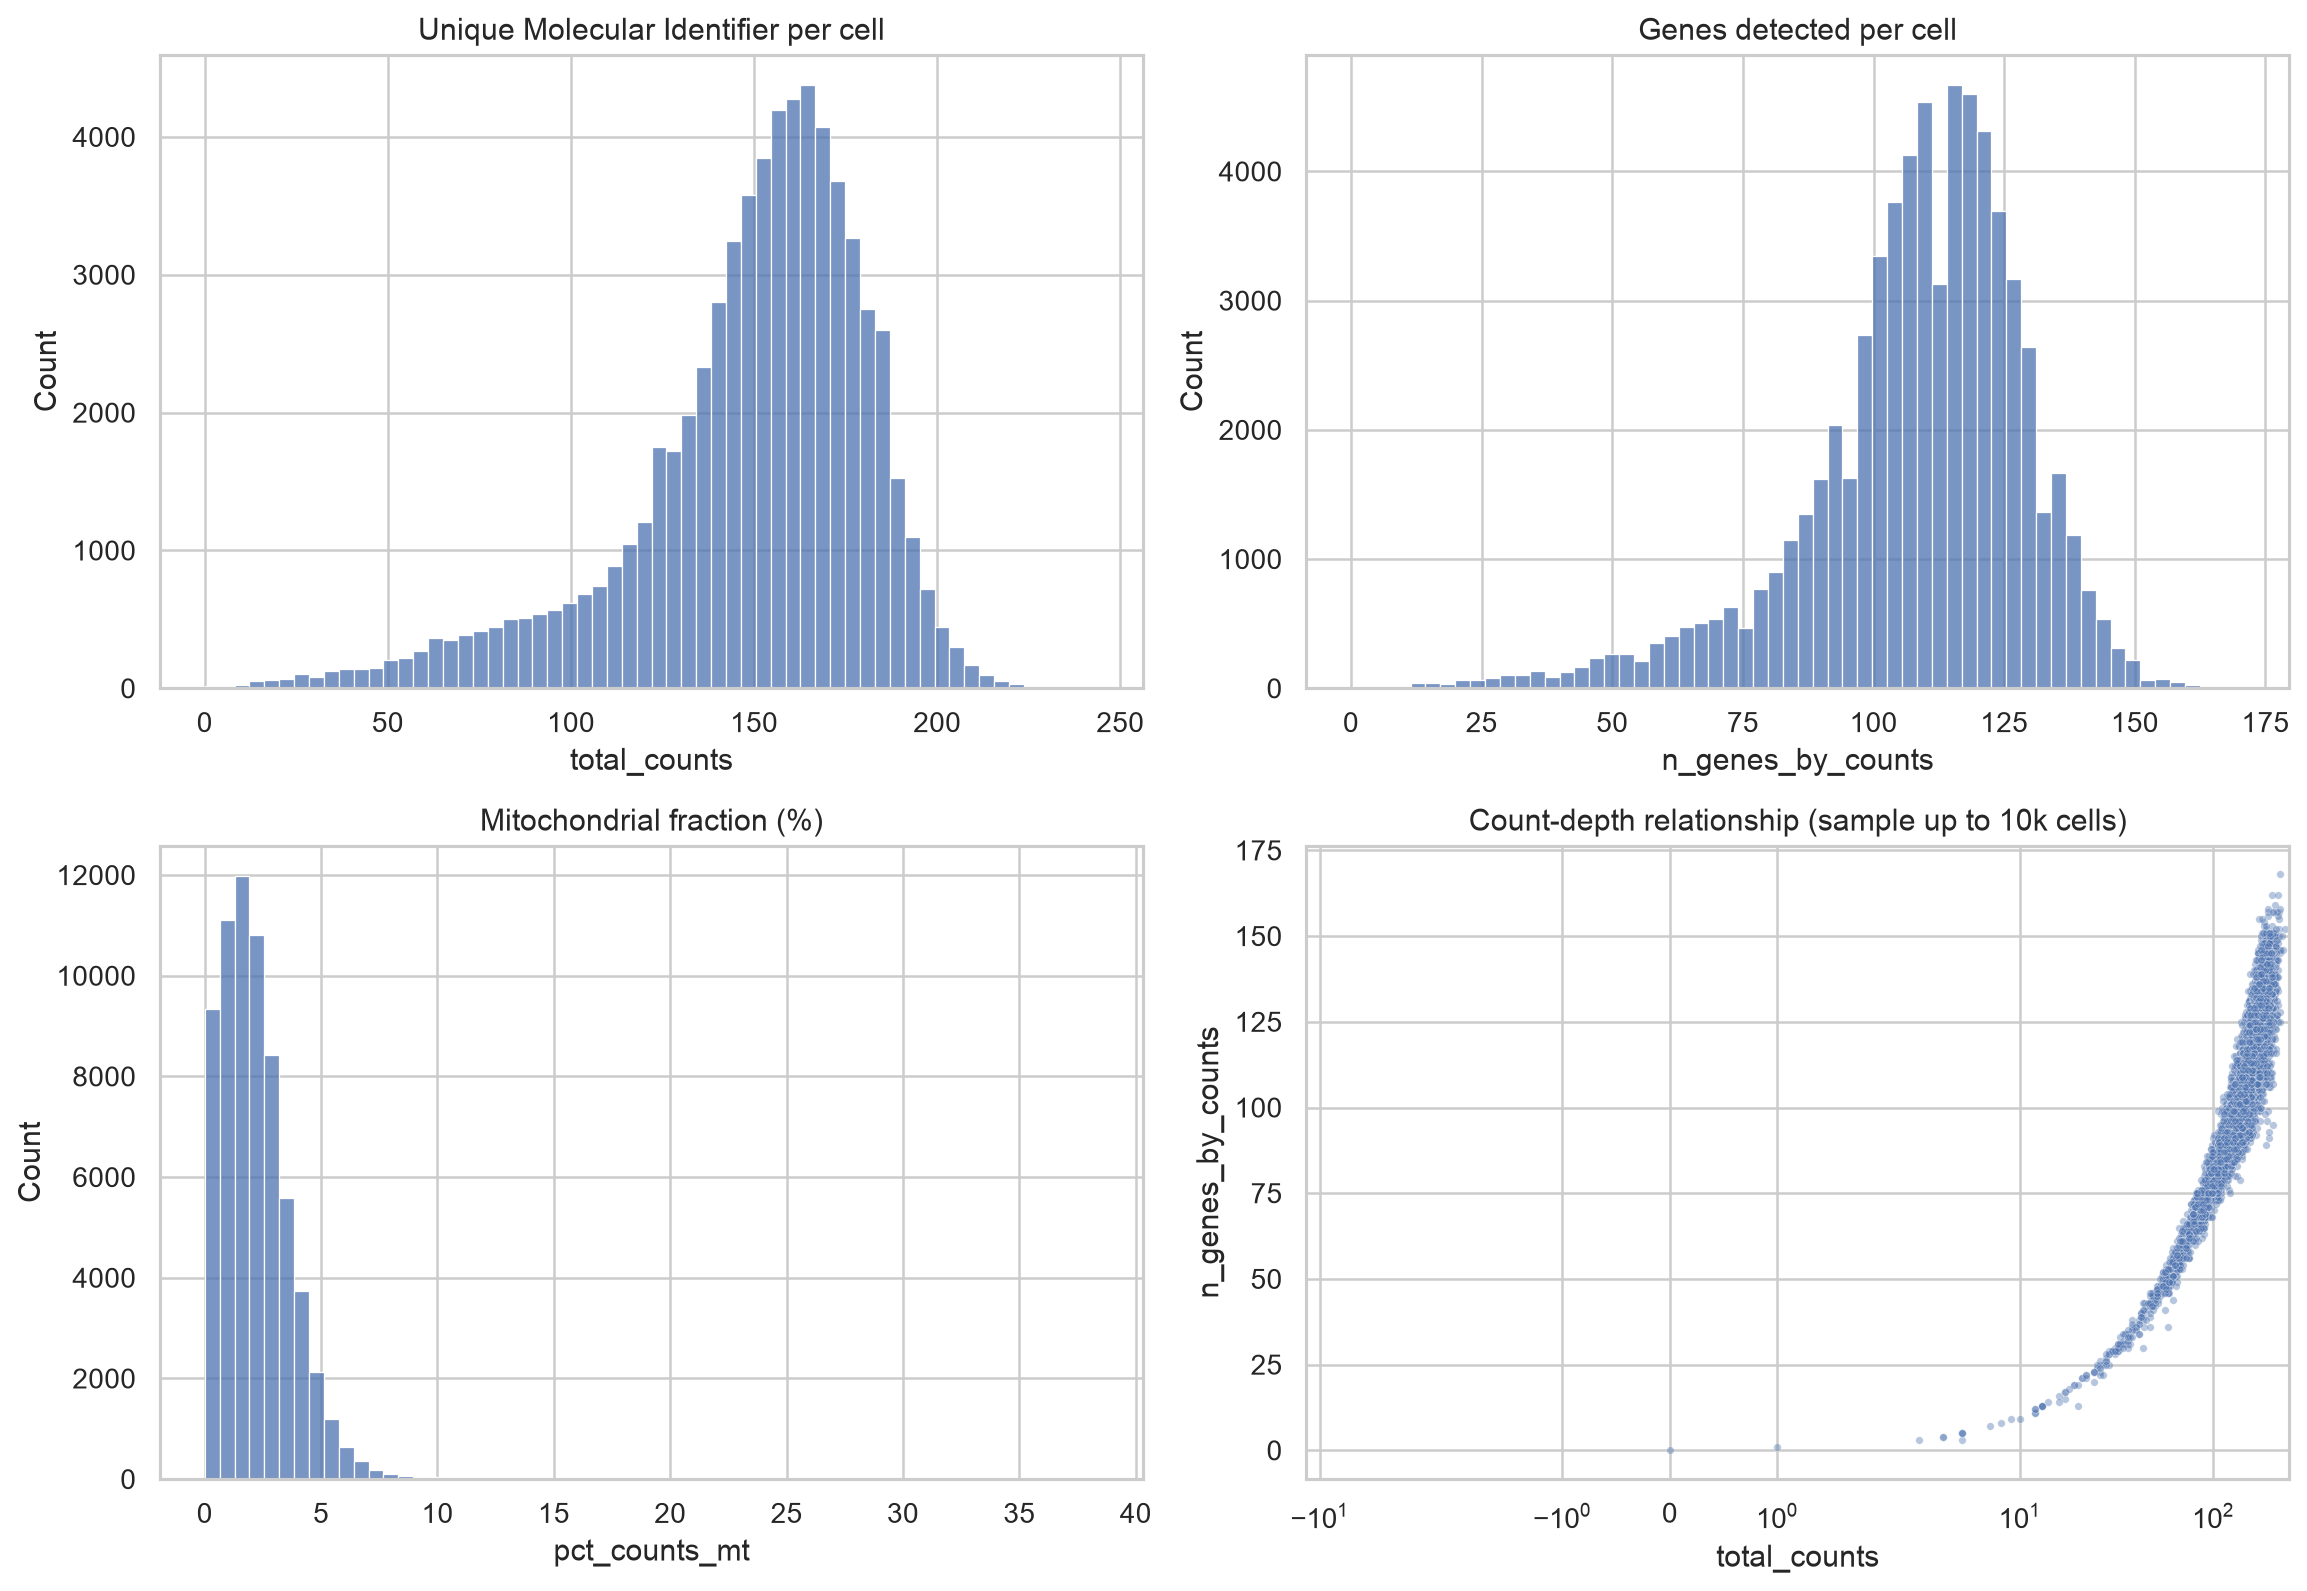

In [12]:
# review 
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col, title in zip(axes.flat[:3],
                          ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
                          ["Unique Molecular Identifier per cell", "Genes detected per cell", "Mitochondrial fraction (%)"]):
    if col in qc.obs:
        print(col)
        sns.histplot(qc.obs[col], bins=60, ax=ax)
        ax.set_title(title)
    else:
        ax.set_visible(False)

sns.scatterplot(data=qc.obs.sample(min(10_000, qc.n_obs), random_state=SEED),
                x="total_counts", y="n_genes_by_counts", s=9, alpha=.4, ax=axes.flat[3])
axes.flat[3].set_xscale("symlog")
axes.flat[3].set_title("Count-depth relationship (sample up to 10k cells)")
# Cells with more captured RNA have higher total counts
plt.tight_layout(); plt.show()



# if "pct_counts_mt" in qc.obs:
#     fig, ax = plt.subplots(figsize=(7, 5))
#     sample = qc.obs.sample(min(10_000, qc.n_obs), random_state=SEED)
#     sns.scatterplot(data=sample, x="total_counts", y="pct_counts_mt", s=9, alpha=.4, ax=ax)
#     ax.set_xscale("symlog")
#     plt.tight_layout(); plt.show()


In [13]:
# qc.var["total_counts"].sort_values(ascending = False) <- print to see better

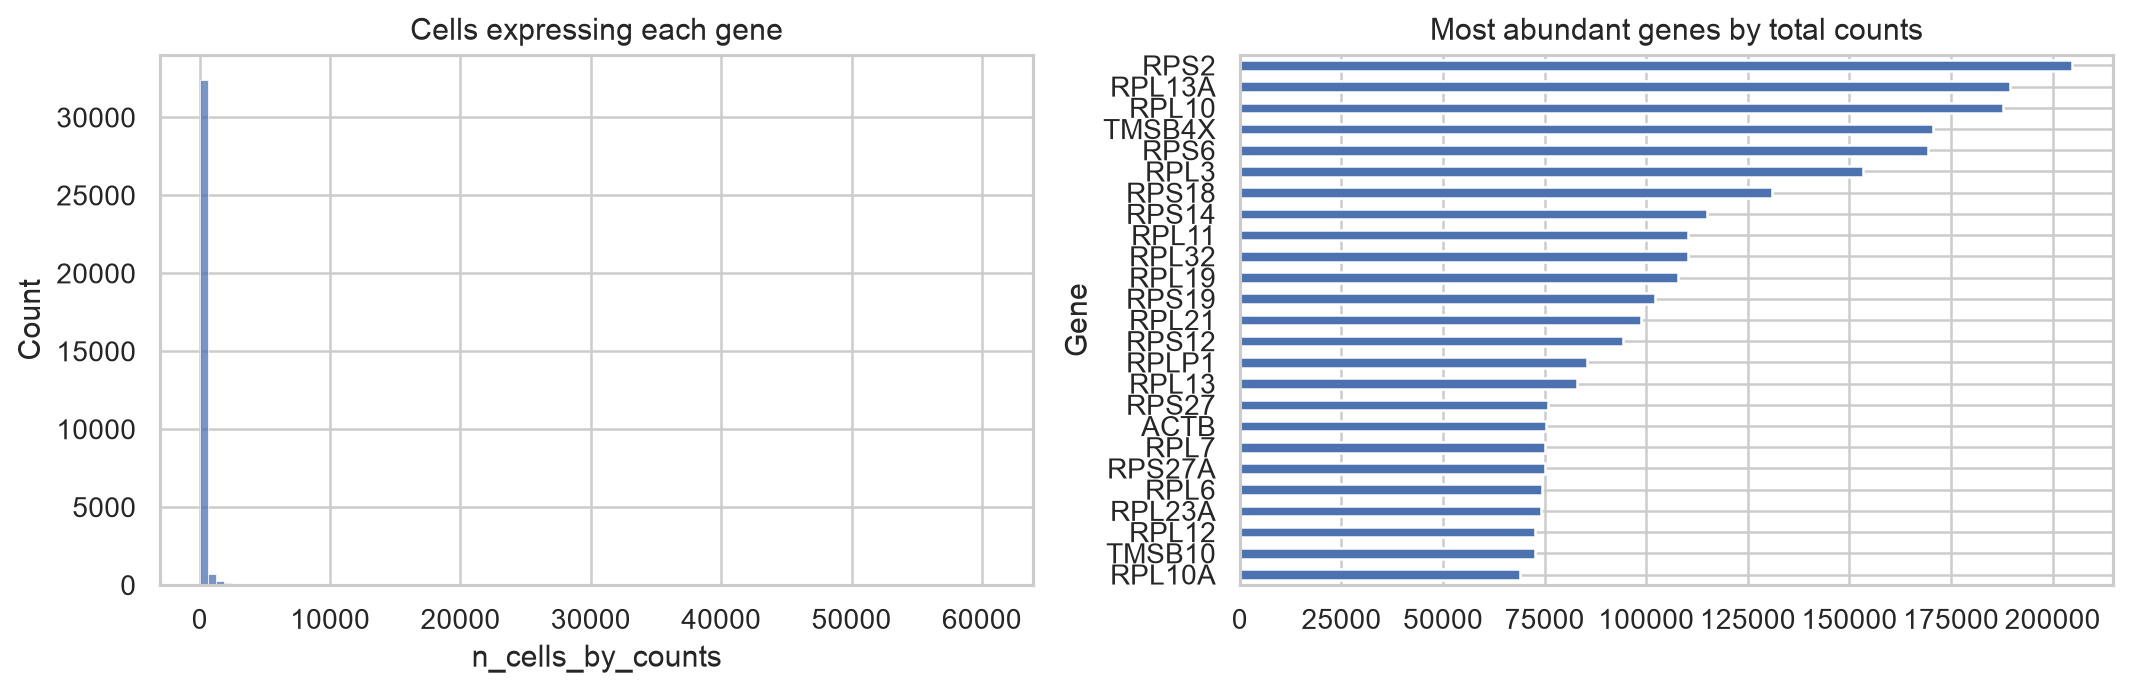

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(qc.var["n_cells_by_counts"], bins=100, ax=ax[0])
# “0 genes are detected in only 17817 cell.”
# “1 gene is detected in only 1986 cell.”
# “2 gene is detected in only 928 cell.”

ax[0].set_title("Cells expressing each gene")


top_genes = qc.var["total_counts"].nlargest(min(25, qc.n_vars)).sort_values()
top_genes.plot.barh(ax=ax[1], title="Most abundant genes by total counts")
plt.tight_layout(); plt.show()


# RPS2, RPL13A  is the most common gene 

### Part 3 (cont.) — Data review and apply QC thresholds

Defaults are moderate starting values for single-cell counts; inspect the distributions and adjust them.

The table reports how many cells each rule would remove, including overlapping exclusions. Gene filtering follows cell filtering. No cell is dropped on mitochondrial percentage when mitochondrial genes were not identifiable.

In [15]:
# You may change these values 
MIN_GENES = 20           
MIN_COUNTS = 1           # drop only truly empty barcodes
MAX_PCT_MT = 10.0        # keep cells with at most 10% mitochondrial expression (99th pct is ~6.8%)
MIN_CELLS_PER_GENE = 3   # after cell filtering, keep genes detected in at least 3 retained cells

LABEL_COL = "celltype"   # class label used for per-class QC diagnostics / guardrail
MIN_CLASS_RETENTION = 0.90  # every class must retain at least this fraction of its cells
# You may change these values 

In [16]:
def build_rules(min_genes, min_counts, max_pct_mt):
    """Return a boolean DataFrame of per-rule exclusion masks for the given thresholds."""
    r = pd.DataFrame(index=qc.obs_names)
    r["few_genes"] = qc.obs.n_genes_by_counts < min_genes
    r["low_counts"] = qc.obs.total_counts < min_counts
    if "pct_counts_mt" in qc.obs:
        r["high_mt"] = qc.obs.pct_counts_mt > max_pct_mt
    return r

# build rule and remove cells 
rules = build_rules(MIN_GENES, MIN_COUNTS, MAX_PCT_MT)
display(pd.DataFrame({"excluded_by_rule": rules.sum(), "percent_of_cells": 100 * rules.mean()}).round(2))
cell_keep = ~rules.any(axis=1)
print(f"Cell retention: {cell_keep.sum():,}/{qc.n_obs:,} ({cell_keep.mean():.1%})")

if LABEL_COL in qc.obs:
    # How many cells each rule drops per class, plus overall per-class retention.
    labels = qc.obs[LABEL_COL]
    per_class = pd.DataFrame({"total": labels.value_counts()})
    for rule_name in rules.columns:
        per_class[f"drop_{rule_name}"] = labels[rules[rule_name].to_numpy()].value_counts()
    per_class["kept"] = labels[cell_keep.to_numpy()].value_counts()
    per_class = per_class.fillna(0).astype(int)
    per_class["retention_%"] = (100 * per_class["kept"] / per_class["total"]).round(1)
    per_class = per_class.sort_values("total")
    print("\nPer-class impact of the current thresholds:")
    display(per_class)
    worst = per_class.loc[per_class["retention_%"].idxmin()]
    print(f"Worst-retained class: {worst.name} at {worst['retention_%']}%")

# global retention vs. worst-class retention
def _sweep(param, values):
    rows = []
    for v in values:
        kw = {"min_genes": MIN_GENES, "min_counts": MIN_COUNTS, "max_pct_mt": MAX_PCT_MT}
        kw[param] = v
        keep = ~build_rules(**kw).any(axis=1)
        row = {"param": param, "value": v,
               "global_retention_%": round(100 * keep.mean(), 1)}
        if LABEL_COL in qc.obs:
            lab = qc.obs[LABEL_COL]
            ret = (lab[keep.to_numpy()].value_counts() / lab.value_counts()).fillna(0)
            row["worst_class_retention_%"] = round(100 * ret.min(), 1)
        rows.append(row)
    return pd.DataFrame(rows)

sweep = pd.concat([
    _sweep("min_genes", [0, 10, 20, 50, 80, 100, 150]),
    _sweep("max_pct_mt", [5, 10, 15, 20, 100]),
    _sweep("min_counts", [1, 40, 80]),
], ignore_index=True)
print("\nThreshold sweep (one parameter varied at a time, others held at chosen defaults):")
display(sweep)

if cell_keep.sum() < 3:  # too few cells
    raise ValueError("QC thresholds retain fewer than three cells. Review the plots and adjust them.")

work = qc[cell_keep.to_numpy(), :].copy()
sc.pp.filter_genes(work, min_cells=MIN_CELLS_PER_GENE)
print("\nAfter cell and gene QC:", work.shape, f" \t\t{work.shape[1]} = {qc.shape[1]} - above number of genes filtered")
if work.n_vars < 3:
    raise ValueError("Too few genes remain. Adjust MIN_CELLS_PER_GENE.")

if LABEL_COL in qc.obs:
    before = qc.obs[LABEL_COL].value_counts()
    after = work.obs[LABEL_COL].value_counts().reindex(before.index).fillna(0).astype(int)
    missing = before.index[after == 0].tolist()
    if missing:
        raise ValueError(f"QC removed entire class(es): {missing}. Loosen the thresholds.")
    retention = after / before
    below = retention[retention < MIN_CLASS_RETENTION]
    if len(below):
        raise ValueError(
            f"Class(es) below the {MIN_CLASS_RETENTION:.0%} retention floor: "
            + ", ".join(f"{c}={retention[c]:.1%}" for c in below.index)
            + ". Loosen the thresholds."
        )
    print(f"\nGuardrail OK: all {len(before)} classes retained >= {MIN_CLASS_RETENTION:.0%} of their cells.")

qc_decisions = pd.DataFrame({"setting": [MIN_GENES, MIN_COUNTS, MAX_PCT_MT if "pct_counts_mt" in qc.obs else "not applied", MIN_CELLS_PER_GENE],
                             "parameter": ["min_genes", "min_counts", "max_pct_mt", "min_cells_per_gene"]})
display(qc_decisions)


#   - CD4+ T Helper2 (your rarest, 92 cells): 91 kept = 98.9%. Only 1 cell dropped.
#   - CD34+ (267 cells): 259 kept = 97.0%. 6 dropped by few_genes, 3 by high_mt.
#   - Every class retains ≥96.4%, so you are not biasing the dataset against any cell type. 
#         The two rare classes you specifically care about are almost fully intact.
  

,excluded_by_rule,percent_of_cells
few_genes,175,0.27
low_counts,1,0.00
high_mt,135,0.20


Cell retention: 65,578/65,877 (99.5%)

Per-class impact of the current thresholds:


,total,drop_few_genes,drop_low_counts,drop_high_mt,kept,retention_%
celltype,,,,,,
CD4+ T Helper2,92,1,0,0,91,98.9
CD34+,267,6,0,3,259,97.0
CD4+/CD45RA+/CD25- Naive T,1802,1,0,1,1800,99.9
Dendritic,2014,63,0,12,1941,96.4
CD14+ Monocyte,2749,4,0,9,2736,99.5
CD4+/CD45RO+ Memory,2945,8,0,6,2931,99.5
CD19+ B,5674,50,1,29,5601,98.7
CD4+/CD25 T Reg,5921,15,0,10,5897,99.6
CD56+ NK,8440,4,0,13,8423,99.8


Worst-retained class: Dendritic at 96.4%

Threshold sweep (one parameter varied at a time, others held at chosen defaults):


,param,value,global_retention_%,worst_class_retention_%
0,min_genes,0,99.8,98.9
1,min_genes,10,99.7,98.5
2,min_genes,20,99.5,96.4
3,min_genes,50,97.7,80.8
4,min_genes,80,90.4,58.1
5,min_genes,100,73.2,44.8
6,min_genes,150,0.5,0.0
7,max_pct_mt,5,95.2,91.3
8,max_pct_mt,10,99.5,96.4
9,max_pct_mt,15,99.7,96.8


filtered out 20739 genes that are detected in less than 3 cells

After cell and gene QC: (65578, 13200)  		13200 = 33939 - above number of genes filtered

Guardrail OK: all 11 classes retained >= 90% of their cells.


,setting,parameter
0,20.0,min_genes
1,1.0,min_counts
2,10.0,max_pct_mt
3,3.0,min_cells_per_gene


#### Part 4 — Normalization and feature selection (HVGs)
*Contribution: puts expression on a comparable, denoised scale so cell-to-cell distances reflect biology, not sequencing depth — the precondition for every graph and embedding.*

Save the validated filtered counts in a layer, then normalize each cell to 10,000 counts and log-transform. The resulting work.X contains log-normalized values.
Highly variable genes (HVGs) are selected from this matrix. Gene selection is used for PCA, while all filtered genes remain available for inspection.

> **Scaling intentionally omitted.** We do not z-score genes (`sc.pp.scale`) before PCA. HVG + log1p already tame the dynamic range, and adding scaling would shift the PCA geometry that our kNN graph and homophily numbers are measured on. Scaling is kept as an optional ablation (see `progress.md` §5), not part of the default pipeline.

#### Highly Variable Genes

| Gene  | Cell 1 | Cell 2 | Cell 3 | Cell 4 |
| --- | --- | --- |  --- | --- |
| A  | 10 | 10 | 10 | 10 |
| B  | 0 | 0 | 20 | 20 |

Gene B varies more than A, thus help distinguish first 2 cells from last 2 cells 

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
Highly Variable Genes: 2000


,means,dispersions,dispersions_norm
Gene,,,
IGLC3,0.950222,5.950293,14.771790
PF4,0.442224,5.474431,13.313467
GNG11,0.374429,5.268606,10.878819
IGHA2,0.182240,6.160908,10.792615
FCER1A,0.277582,5.247428,10.628313
CAVIN2,0.333713,5.228267,10.401662
IGHA1,0.267722,6.093219,10.395912
PPBP,1.173055,6.663555,10.014354
IGHG2,0.062582,5.964511,9.641601


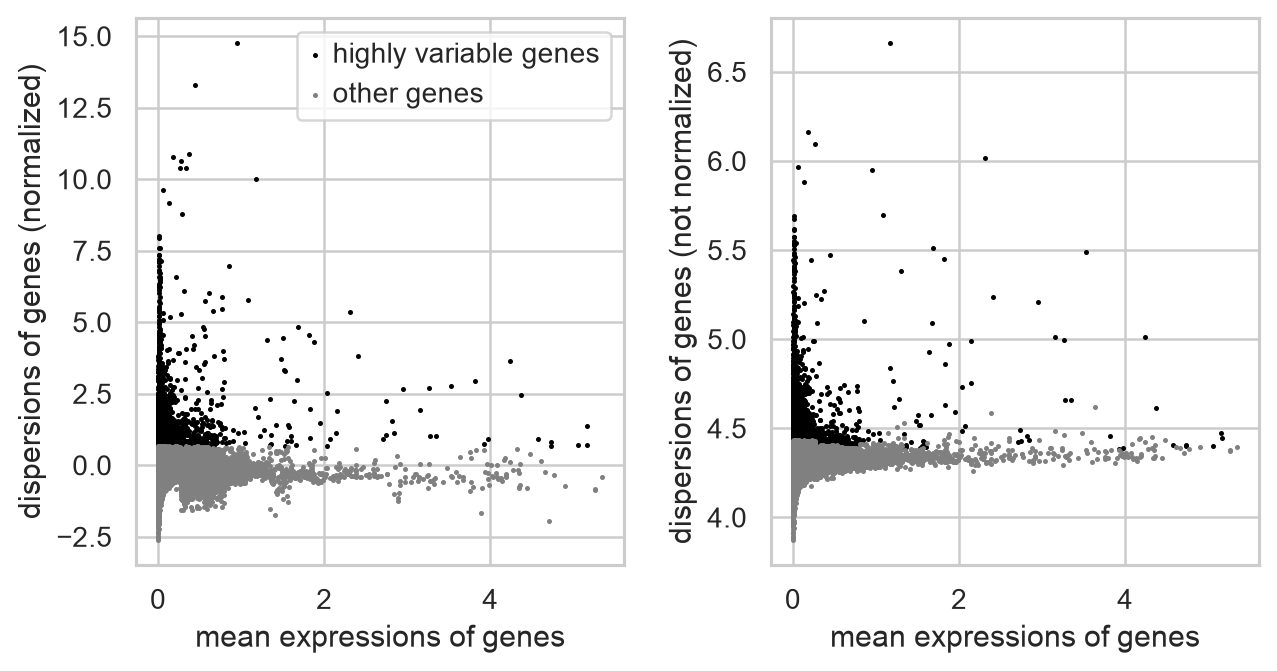

In [17]:
work.layers["counts"] = work.X.copy()
sc.pp.normalize_total(work, target_sum=10000)  # divides gene value by cell total * 10000 
# if a gene has 10 counts in a cell containing 2000 total count, this equals to 10/2000 * 10000 = 50 
sc.pp.log1p(work)


work.layers["log_normalized"] = work.X.copy()
n_hvg = min(2000, work.n_vars - 1)
sc.pp.highly_variable_genes(work, n_top_genes=n_hvg, flavor="seurat", inplace=True)

# Highly variable gene is used for expression differs strongly across cell

print("Highly Variable Genes:", int(work.var.highly_variable.sum()))

top_hvgs = (
    work.var.loc[
        work.var["highly_variable"],
        ["means", "dispersions", "dispersions_norm"]
    ]
    .dropna(subset=["dispersions_norm"])
    .sort_values("dispersions_norm", ascending=False)
)

display(top_hvgs.head(10)) # Top divisive genes 
sc.pl.highly_variable_genes(work)


#### Part 5 & 6 — Representation (PCA), neighbourhood graph and exploratory clusters
*Contribution: PCA is the core dimensionality reduction — it compresses ~13,200 noisy genes into 30 lineage axes that become the node features `P`; the kNN graph built on it is the structure the GNNs message-pass over.*

The neighborhood graph and clusters are derived from the same file.

Leiden groups are exploratory clusters, not cell type labels.

PCA uses HVGs only, with no covariate regression or whole-matrix densification.

In [18]:
# You may change this 
#   SUBSAMPLE=None -> use all cells
#   SUBSAMPLE=5000 -> STRATIFIED subsample to 5k cells for the heavier
#                     manifold methods (LLE / t-SNE) to speed things up.
#   Stratified = rare classes (e.g. CD4+ T Helper2, 92 cells) stay represented.

SUBSAMPLE = 10000  # None = all cells; an int = stratified subsample for faster LLE/t-SNE
# You may change this 


#### PCA
scRNA-seq is ~13,200 genes wide, extremely sparse and noisy, with highly
correlated genes (co-expressed programs). Raw gene space suffers the curse
of dimensionality — cell-to-cell distances become unreliable.


PCA finds the ~30–50 orthogonal directions of greatest variance. For PBMCs
these top PCs track real biological axes (T vs. B vs. myeloid lineage
programs). This denoises (drops low-variance noise dimensions) and
compresses (30 numbers per cell instead of 13,200).

computing PCA
    with n_comps=50
    finished (0:00:00)


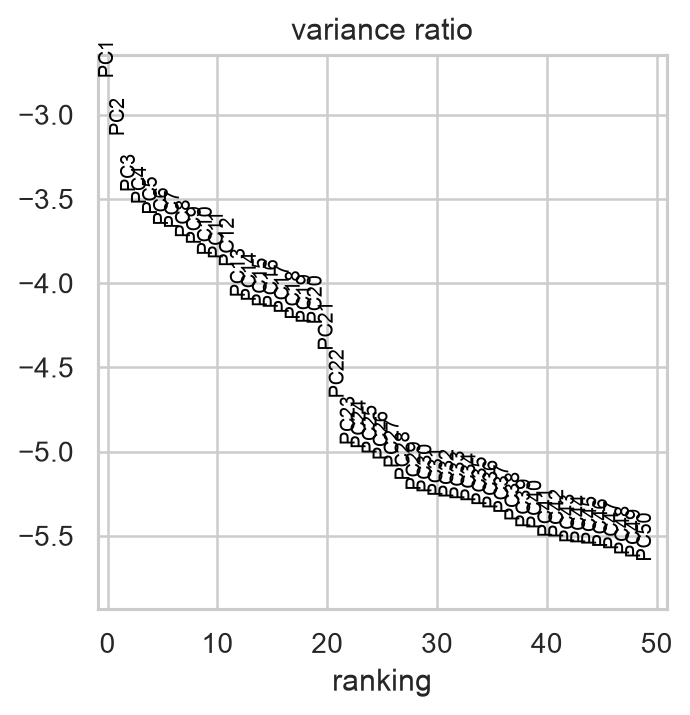

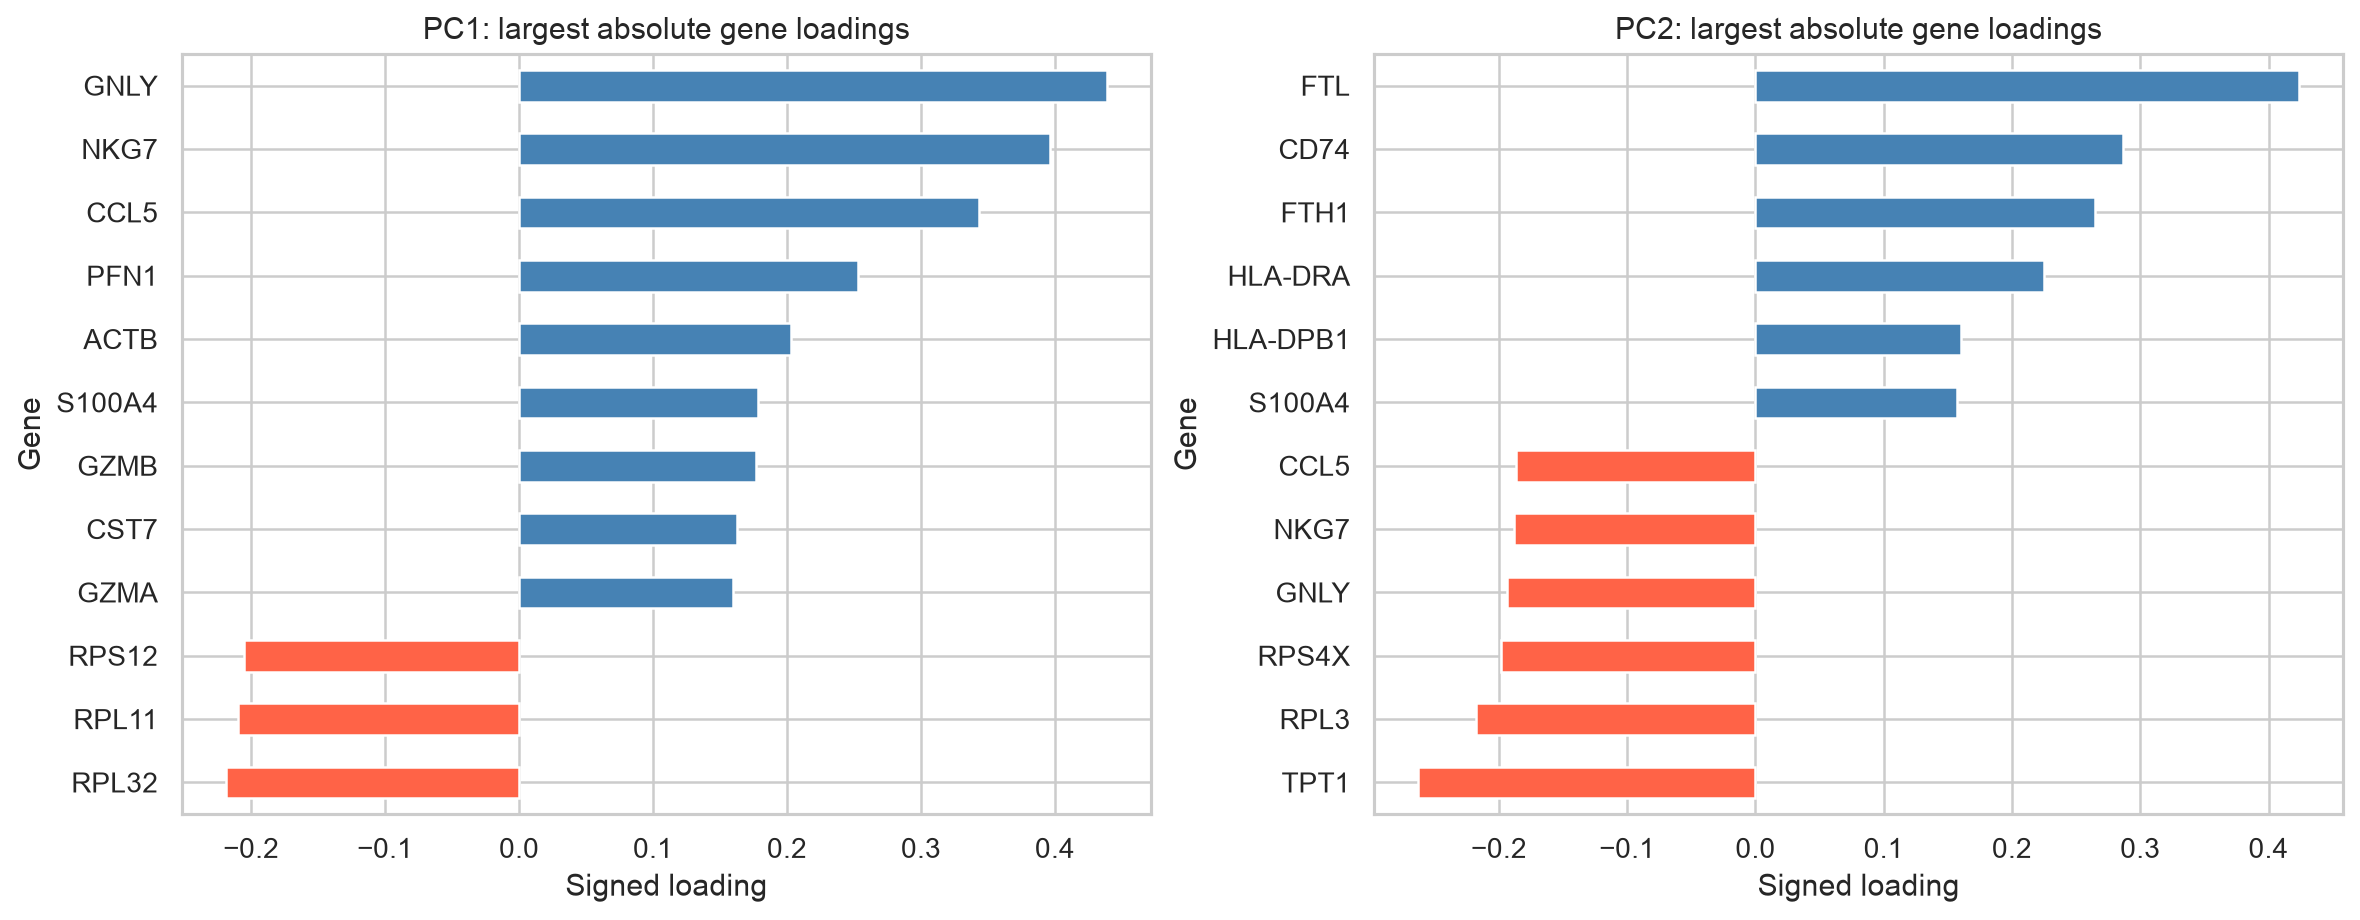

PCs calculated: 50 PCs used for neighborhoods: 50


In [19]:

eda = work  # kept for backward reference; full-graph work happens on `work`


def plot_embedding(adata_view, key, title, color=("celltype",)):
    """Scatter adata_view.obsm[key], colored by one or more obs columns.

    key is the obsm key (e.g. 'X_pca'); scanpy's basis is the key without the 'X_' prefix.
    """
    basis = key[2:] if key.startswith("X_") else key
    for c in color:
        if c in adata_view.obs:
            sc.pl.embedding(adata_view, basis=basis, color=c, title=f"{title} - {c}", show=True)
        else:
            print(f"[plot_embedding] skipping color '{c}' (not in obs)")


# PCA / neighbors / Leiden / homophily / split ALL run on the FULL graph (work) for accuracy.
# Only the slow manifold embeddings (LLE/Laplacian/t-SNE/UMAP) use a subsample (see that cell).
N_PCS = min(50, work.n_obs - 1, work.n_vars - 1)
N_PCS_USE = min(50, N_PCS)  # PCs fed into neighbors / manifolds
pca_kwargs = dict(n_comps=N_PCS, svd_solver="arpack")
params = inspect.signature(sc.pp.pca).parameters
if "rng" in params:
    pca_kwargs["rng"] = SEED
else:
    pca_kwargs["random_state"] = SEED
# All work genes are already the selected HVGs.
sc.pp.pca(work, **pca_kwargs)
sc.pl.pca_variance_ratio(work, log=True, n_pcs=N_PCS)
P = np.asarray(work.obsm["X_pca"][:, :N_PCS_USE], dtype=np.float64)
# PCA scatter is drawn in the combined embedding comparison at the end of Section 5.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for pc, ax in enumerate(axes):
    loading = pd.Series(work.varm["PCs"][:, pc], index=work.var_names)
    selected = loading.loc[loading.abs().nlargest(12).index].sort_values()
    selected.plot.barh(ax=ax, color=["tomato" if v < 0 else "steelblue" for v in selected])
    ax.set_title(f"PC{pc + 1}: largest absolute gene loadings")
    ax.set_xlabel("Signed loading")
plt.show()
print("PCs calculated:", N_PCS, "PCs used for neighborhoods:", P.shape[1])


Why Leiden specifically (vs. k-means or hierarchical):
  - It's graph-based, so it operates directly on the kNN graph you already built — consistent with everything else. k-means would work on PCA coordinates with a different notion of distance and would force spherical, equal-ish
  clusters.
  - It finds communities of arbitrary shape by maximizing modularity (dense within-cluster edges, sparse between). Cell populations aren't spherical blobs; k-means handles them poorly.
  - It doesn't require you to pick the number of clusters — you set a resolution, and it discovers however many communities exist. k-means needs k up front, which you don't know.
  - Leiden is the modern standard in single-cell (an improvement on Louvain that fixes disconnected-community artifacts).
  
  Leiden is doing unsupervised sanity-checking:
  - Do data-driven communities line up with the annotated cell types? (If Leiden clusters cleanly match celltypes, your graph/PCA captured real biology.)
  - It gives a coloring for the embedding plots so you can see structure independent of the labels.

In [20]:
# Neighbor graph + Leiden clustering on the PCA space (FULL graph: work).
# Leiden groups are exploratory clusters, NOT cell-type labels.
sc.pp.neighbors(work, n_neighbors=15, n_pcs=N_PCS_USE, use_rep="X_pca", random_state=SEED)
try:
    sc.tl.leiden(work, resolution=0.6, key_added="leiden",
                 flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
except TypeError:
    sc.tl.leiden(work, resolution=0.6, key_added="leiden", random_state=SEED)
print("Leiden cluster sizes:")
print(work.obs["leiden"].value_counts())


computing neighbors
    finished (0:00:17)
running Leiden clustering
    finished (0:00:01)
Leiden cluster sizes:
leiden
0     13161
7     10298
5      5878
8      4822
1      4229
9      4034
10     3973
6      3894
12     3832
11     3564
2      3122
3      2927
4      1691
13      153
Name: count, dtype: int64


## Part 7 — Soundness analyses: homophily audit
*Contribution: measures the project's central premise instead of asserting it (global edge homophily = 0.412), and — with the coarse-vs-fine cell and the stratified split that follow — turns the thesis into evidence and fixes one reusable evaluation protocol for Steps 2–4.*

The project hypothesis was that **rare** cells (e.g. CD34+) sit at **heterophilous** boundaries where message passing averages their features into majority neighbours. That is an *assertion* until measured — and the measurement reframed it: heterophily tracks **label granularity** (closely-related T subtypes), not rarity.

Here we quantify, on the kNN graph, what fraction of each class's edges stay within-class (edge homophily). High = homophilous (neighbours share its label); low = heterophilous (the regime the gated model targets). We report whatever we find — a homophilous rare class is a valid negative result.

In [21]:
# Homophily audit on the FULL kNN graph (work.obsp['connectivities']).
# Edge homophily = fraction of edges whose two endpoints share the same celltype label.
import scipy.sparse as sp
import pandas as pd

LABEL_COL = "celltype"
assert LABEL_COL in work.obs, f"{LABEL_COL} not found in work.obs"
assert "connectivities" in work.obsp, "Run the neighbors/Leiden cell first."

# Binarise + symmetrise the adjacency, drop self-loops, keep upper triangle for unique edges.
A = (work.obsp["connectivities"] > 0).astype(int)
A = A.maximum(A.T)
A = sp.triu(A, k=1).tocoo()
src, dst = A.row, A.col

codes = work.obs[LABEL_COL].astype("category").cat.codes.to_numpy()
same = codes[src] == codes[dst]

print(f"Global edge homophily: {same.mean():.3f}  (edges={len(src):,})")

# Per-class edge homophily: of all edges incident to class c, fraction that are within-class.
rows = []
classes = work.obs[LABEL_COL].astype("category").cat.categories
for ci, cname in enumerate(classes):
    incident = (codes[src] == ci) | (codes[dst] == ci)
    n_inc = int(incident.sum())
    within = int((incident & same).sum())
    rows.append({
        "celltype": cname,
        "n_cells": int((codes == ci).sum()),
        "incident_edges": n_inc,
        "within_class_edges": within,
        "homophily": round(within / n_inc, 3) if n_inc else float("nan"),
    })
homophily_df = pd.DataFrame(rows).sort_values("n_cells").reset_index(drop=True)
display(homophily_df)

HETERO_THRESHOLD = 0.5
hetero = homophily_df[homophily_df["homophily"] < HETERO_THRESHOLD]
if len(hetero):
    print(f"Heterophilous classes (homophily < {HETERO_THRESHOLD}) — the regime the gated model targets:")
    print(", ".join(f"{r.celltype}={r.homophily}" for r in hetero.itertuples()))
else:
    print(f"No class below homophily {HETERO_THRESHOLD}: the heterophily assertion is NOT supported on this graph.")
    print("That is a valid finding — discuss it rather than assuming the hypothesis holds.")


Global edge homophily: 0.407  (edges=764,669)


,celltype,n_cells,incident_edges,within_class_edges,homophily
0,CD4+ T Helper2,91,2026,2,0.001
1,CD34+,259,3686,1587,0.431
2,CD4+/CD45RA+/CD25- Naive T,1800,45030,1054,0.023
3,Dendritic,1941,31494,4938,0.157
4,CD14+ Monocyte,2736,39111,18227,0.466
5,CD4+/CD45RO+ Memory,2931,65272,2384,0.037
6,CD19+ B,5601,96553,34738,0.360
7,CD4+/CD25 T Reg,5897,126147,10309,0.082
8,CD56+ NK,8423,120419,61328,0.509
9,CD8+/CD45RA+ Naive Cytotoxic,16007,329902,85300,0.259


Heterophilous classes (homophily < 0.5) — the regime the gated model targets:
CD4+ T Helper2=0.001, CD34+=0.431, CD4+/CD45RA+/CD25- Naive T=0.023, Dendritic=0.157, CD14+ Monocyte=0.466, CD4+/CD45RO+ Memory=0.037, CD19+ B=0.36, CD4+/CD25 T Reg=0.082, CD8+/CD45RA+ Naive Cytotoxic=0.259, CD8+ Cytotoxic T=0.254


In [22]:
# Coarse vs. fine homophily: is the heterophily a label-granularity effect?
# Collapse closely-related T-cell subtypes into one "T cell" label, keep other lineages,
# then recompute edge homophily on the SAME graph (reuses src/dst/same from the audit cell).
def to_coarse(label):
    l = str(label)
    t_markers = ("T Helper", "Naive T", "Memory", "T Reg", "Cytotoxic")
    is_t = any(m in l for m in t_markers) or l.startswith("CD8") or l.startswith("CD4")
    return "T cell" if is_t else l

coarse = work.obs[LABEL_COL].astype(str).map(to_coarse).astype("category")
work.obs["celltype_coarse"] = coarse

print("Label collapse mapping (verify the T subtypes are grouped correctly):")
mapping = (pd.DataFrame({"fine": work.obs[LABEL_COL].astype(str), "coarse": coarse.astype(str)})
           .drop_duplicates().sort_values(["coarse", "fine"]).reset_index(drop=True))
display(mapping)

ccodes = coarse.cat.codes.to_numpy()
same_coarse = ccodes[src] == ccodes[dst]
global_fine, global_coarse = float(same.mean()), float(same_coarse.mean())
print(f"\nGlobal edge homophily | fine: {global_fine:.3f} -> coarse: {global_coarse:.3f} "
      f"(delta +{global_coarse - global_fine:.3f})")

rows = []
for ci, cname in enumerate(coarse.cat.categories):
    incident = (ccodes[src] == ci) | (ccodes[dst] == ci)
    n_inc = int(incident.sum())
    within = int((incident & same_coarse).sum())
    rows.append({"coarse_celltype": cname, "n_cells": int((ccodes == ci).sum()),
                 "incident_edges": n_inc,
                 "homophily_coarse": round(within / n_inc, 3) if n_inc else float("nan")})
coarse_df = pd.DataFrame(rows).sort_values("n_cells").reset_index(drop=True)
display(coarse_df)

if global_coarse >= 0.5 and global_fine < 0.5:
    print("Finding: merging T subtypes flips the graph from heterophilous to homophilous.")
    print("=> The fine-grained heterophily is largely a LABEL-GRANULARITY effect (subtype confusion),")
    print("   not intrinsic structure. The gated model targets this subtype-confusion regime.")
else:
    print("Finding: homophily rose by the delta above but subtype merging does not fully explain it;")
    print("   residual heterophily remains at the lineage level — discuss both contributions.")


Label collapse mapping (verify the T subtypes are grouped correctly):


,fine,coarse
0,CD14+ Monocyte,CD14+ Monocyte
1,CD19+ B,CD19+ B
2,CD34+,CD34+
3,CD56+ NK,CD56+ NK
4,Dendritic,Dendritic
5,CD4+ T Helper2,T cell
6,CD4+/CD25 T Reg,T cell
7,CD4+/CD45RA+/CD25- Naive T,T cell
8,CD4+/CD45RO+ Memory,T cell
9,CD8+ Cytotoxic T,T cell



Global edge homophily | fine: 0.407 -> coarse: 0.802 (delta +0.396)


,coarse_celltype,n_cells,incident_edges,homophily_coarse
0,CD34+,259,3686,0.431
1,Dendritic,1941,31494,0.157
2,CD14+ Monocyte,2736,39111,0.466
3,CD19+ B,5601,96553,0.360
4,CD56+ NK,8423,120419,0.509
5,T cell,46618,624456,0.789


Finding: merging T subtypes flips the graph from heterophilous to homophilous.
=> The fine-grained heterophily is largely a LABEL-GRANULARITY effect (subtype confusion),
   not intrinsic structure. The gated model targets this subtype-confusion regime.


#### 5c. Transductive train / val / test split
Node-level masks for semi-supervised node classification. All nodes/edges stay in the graph; only the **labels** are masked. The split is **stratified by celltype** so even the rarest class (CD4+ T Helper2, 92 cells) appears in every mask, and it is seeded for reproducibility. The same val/test masks are reused across every model for fair comparison; the label-scarcity curves (1/2/5/10/20%) later subsample only the train mask.

In [23]:
# Stratified transductive split -> boolean masks in work.obs: train_mask / val_mask / test_mask.
from sklearn.model_selection import train_test_split

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.60, 0.20, 0.20
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

y = work.obs[LABEL_COL].to_numpy()
idx = np.arange(work.n_obs)

train_idx, rest_idx = train_test_split(idx, train_size=TRAIN_FRAC, stratify=y, random_state=SEED)
val_share = VAL_FRAC / (VAL_FRAC + TEST_FRAC)
val_idx, test_idx = train_test_split(rest_idx, train_size=val_share, stratify=y[rest_idx], random_state=SEED)

for name, arr in [("train_mask", train_idx), ("val_mask", val_idx), ("test_mask", test_idx)]:
    m = np.zeros(work.n_obs, dtype=bool)
    m[arr] = True
    work.obs[name] = m

tm, vm, sm = work.obs["train_mask"].to_numpy(), work.obs["val_mask"].to_numpy(), work.obs["test_mask"].to_numpy()
assert not (tm & vm).any() and not (tm & sm).any() and not (vm & sm).any(), "Masks overlap!"
assert (tm | vm | sm).all(), "Some cells are unassigned!"

split_counts = pd.DataFrame({
    "train": work.obs.loc[tm, LABEL_COL].value_counts(),
    "val": work.obs.loc[vm, LABEL_COL].value_counts(),
    "test": work.obs.loc[sm, LABEL_COL].value_counts(),
}).fillna(0).astype(int)
split_counts = split_counts.loc[work.obs[LABEL_COL].value_counts().sort_values().index]
print(f"Split sizes -> train {tm.sum():,} | val {vm.sum():,} | test {sm.sum():,}")
display(split_counts)
missing = split_counts[(split_counts == 0).any(axis=1)]
if len(missing):
    print("WARNING: these classes are absent from at least one split; per-class metrics will be unreliable:")
    print(", ".join(missing.index))
else:
    print("All classes present in train/val/test.")


Split sizes -> train 39,346 | val 13,116 | test 13,116


,train,val,test
celltype,,,
CD4+ T Helper2,55,18,18
CD34+,155,52,52
CD4+/CD45RA+/CD25- Naive T,1080,360,360
Dendritic,1165,388,388
CD14+ Monocyte,1642,547,547
CD4+/CD45RO+ Memory,1758,586,587
CD19+ B,3360,1121,1120
CD4+/CD25 T Reg,3538,1180,1179
CD56+ NK,5054,1684,1685


All classes present in train/val/test.


#### Part 8 — Feature engineering: augmenting the PCA node features
*Contribution: injects known biology (markers) and topology (graph features) that PCA averages away — the lever for minority-class performance — with per-block toggles for clean ablation and a block→column map for Step 4 attribution.*

The models so far would see only the 50-D PCA matrix `P`. Here we build an
**augmented node-feature matrix** `work.obsm["X_features"]` from up to four
**independently ablatable** blocks:

1. **PCA** (`P`, 50-D) — the denoised shared representation.
2. **Marker genes** — log-normalised expression of a curated PBMC panel; injects
   known biology that PCA averages away (biggest expected lift for minority classes).
3. **QC covariates** — `total_counts`, `n_genes_by_counts`, `pct_counts_mt`; depth/complexity can be weakly type-informative.
4. **Graph structure** — label-free per-node topology (degree, clustering, mean neighbour distance, neighbourhood entropy, reciprocity, dispersion).

Soundness rules: every block is a **toggle**, not a silent default (ablate on
macro-F1 later); appended blocks are **z-scored using train-mask statistics only**
(leakage-safe); and **local homophily is computed as an analysis column only**,
never fed to the classifier (it uses labels).

**Marker-gene block.** A curated PBMC panel grouped by lineage, intersected with
the genes that survived QC. `work` keeps all ~13,200 post-QC genes, so markers are
read straight from the log-normalised matrix. Any missing marker is reported, not
fatal — note CD34 is expected to be absent (nonzero in only one raw cell; this
FACS-labelled dataset does not carry a detectable CD34 signal, a real limitation
for the CD34+ class).

In [24]:
# Curated PBMC marker panel (lineage -> genes); intersect with available genes.
MARKER_PANEL = {
    "T":        ["CD3D", "CD3E", "CD8A", "CD4", "IL7R", "CCR7", "S100A4"],
    "Treg":     ["FOXP3", "IL2RA"],
    "B":        ["MS4A1", "CD79A", "CD79B"],
    "NK":       ["GNLY", "NKG7", "KLRD1"],
    "Monocyte": ["LYZ", "CD14", "FCGR3A", "MS4A7"],
    "DC":       ["FCER1A", "CST3"],
    "Platelet": ["PPBP"],
    "Progenitor": ["CD34", "CD38", "SELL"],
}
marker_genes, report = [], []
for lineage, genes in MARKER_PANEL.items():
    kept = [g for g in genes if g in work.var_names]
    missing = [g for g in genes if g not in work.var_names]
    marker_genes += kept
    report.append({"lineage": lineage, "kept": ", ".join(kept) or "—",
                   "missing": ", ".join(missing) or "—"})
    if not kept:
        print(f"WARNING: lineage '{lineage}' has no available markers.")
display(pd.DataFrame(report))

Xm = work[:, marker_genes].X
X_markers = np.asarray(Xm.todense() if sp.issparse(Xm) else Xm, dtype=np.float64)
print(f"Marker block: {X_markers.shape[1]} genes -> {X_markers.shape}")

,lineage,kept,missing
0,T,"CD3D, CD3E, CD8A, CD4, IL7R, CCR7, S100A4",—
1,Treg,"FOXP3, IL2RA",—
2,B,"MS4A1, CD79A, CD79B",—
3,NK,"GNLY, NKG7, KLRD1",—
4,Monocyte,"LYZ, CD14, FCGR3A, MS4A7",—
5,DC,"FCER1A, CST3",—
6,Platelet,PPBP,—
7,Progenitor,"CD38, SELL",CD34


Marker block: 24 genes -> (65578, 24)


**QC covariate block.** Three per-cell quality metrics as features. Normalisation
deliberately removed library size, but raw depth/complexity still carries mild
cell-type signal (e.g. monocytes vs. small lymphocytes). Cheap to add and ablate.

In [25]:
QC_COLS = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
missing_qc = [c for c in QC_COLS if c not in work.obs]
if missing_qc:  # recompute if a column is absent
    work.var["mt"] = work.var_names.str.upper().str.startswith("MT-")
    sc.pp.calculate_qc_metrics(work, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
X_qc = work.obs[QC_COLS].to_numpy(dtype=np.float64)
assert np.isfinite(X_qc).all(), "QC features contain non-finite values"
print(f"QC block: {X_qc.shape}")
display(work.obs.groupby(LABEL_COL, observed=True)[QC_COLS].mean().round(1))

QC block: (65578, 3)


,total_counts,n_genes_by_counts,pct_counts_mt
celltype,,,
CD4+ T Helper2,130.100006,97.2,2.2
CD4+/CD25 T Reg,142.600006,105.2,1.9
CD4+/CD45RA+/CD25- Naive T,144.699997,102.9,1.7
CD4+/CD45RO+ Memory,138.100006,102.0,2.0
CD8+ Cytotoxic T,150.000000,109.1,2.3
CD8+/CD45RA+ Naive Cytotoxic,150.000000,105.3,1.9
CD14+ Monocyte,149.199997,108.3,2.3
CD19+ B,151.800003,106.6,2.3
CD34+,155.800003,103.1,2.1


**Graph-structure block (label-free).** Per-node summaries of the kNN graph, each
measuring something distinct and all computed without labels (so they are safe as
model inputs):

- **degree** - in-degree on the symmetrised graph (how often a cell is chosen as a neighbour); honest local connectivity.
- **clustering** - fraction of a cell's neighbours that are also neighbours of each other (tight core vs. loose boundary).
- **mean_nbr_dist** - mean PCA distance to the cell's kNN neighbours; a direct local-density measure (rare/sparse cells have larger radii).
- **nbr_entropy** - Shannon entropy of the neighbours' **Leiden** cluster membership; a label-free proxy for neighbourhood *mixing* (the structural analogue of heterophily).
- **reciprocity** - fraction of a cell's directed kNN neighbours that reciprocate; low reciprocity flags the spurious cross-type edges the gated model should down-weight.
- **nbr_dispersion** - distance from the cell to its neighbours' PCA centroid; a boundary-vs-core geometric detector.

Boundary cells (high dispersion / high entropy) are hypothesised to be
over-represented among the heterophilous classes - the regime the gate targets.

> **Why not classic centrality (PageRank, Katz, eigenvector, betweenness)?** Our
> graph is a **kNN graph built from PCA**: every node has (near) the same degree
> (k=15) by construction, with no hubs or scale-free structure. On such a
> degree-regular graph these centrality measures collapse into **local-density
> proxies** - they add little beyond `degree` and say nothing about *class
> identity*. Betweenness additionally costs ~O(V\u00b7E) (prohibitive at 65k nodes) and
> only re-discovers boundary cells that `nbr_entropy`/`nbr_dispersion` detect far
> more cheaply. We therefore use **neighbourhood-heterogeneity** features
> (entropy, dispersion, reciprocity, mean distance), which directly measure the
> boundary/mixing structure central to this project.

Graph block: (65578, 6) -> ['degree', 'clustering', 'mean_nbr_dist', 'nbr_entropy', 'reciprocity', 'nbr_dispersion']


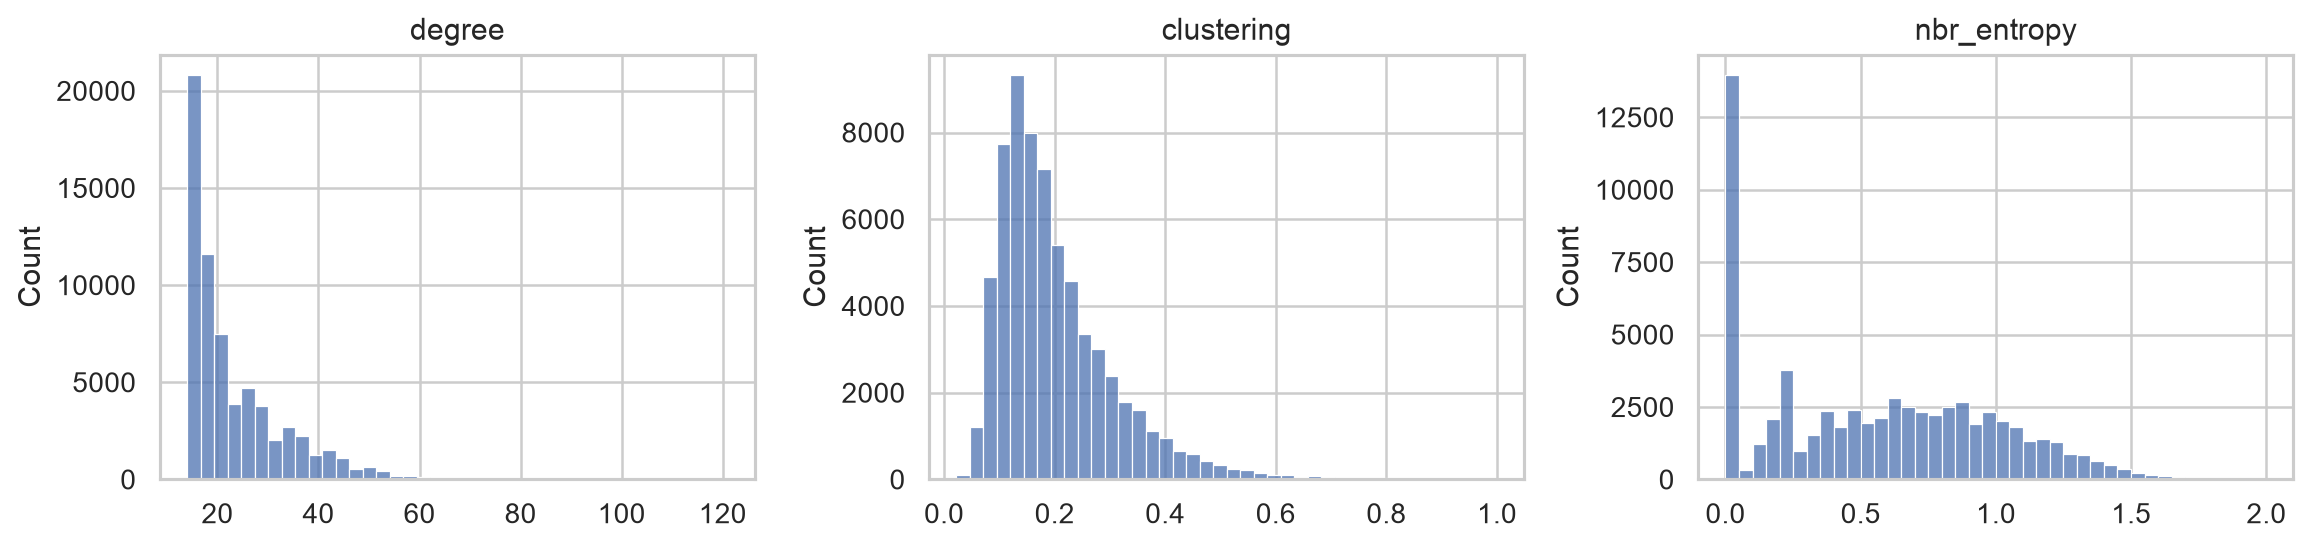

In [26]:
import igraph as ig
A = (work.obsp["connectivities"] > 0).astype(int); A = A.maximum(A.T)
Au = sp.triu(A, k=1).tocoo()
g = ig.Graph(n=work.n_obs, edges=list(zip(Au.row.tolist(), Au.col.tolist())), directed=False)

deg   = np.asarray(g.degree(), dtype=np.float64)
clust = np.asarray(g.transitivity_local_undirected(mode="zero"), dtype=np.float64)

# mean neighbour distance (local density): mean of each row's kNN distances
Dk = work.obsp["distances"].tocsr()
mean_nbr_dist = np.asarray(Dk.sum(1)).ravel() / np.clip(np.diff(Dk.indptr), 1, None)

# neighbourhood entropy: Shannon entropy of neighbours' Leiden clusters (label-free; uses unsupervised leiden)
lei = work.obs["leiden"].astype("category").cat.codes.to_numpy()
Dbin = (Dk > 0).astype(int); Dbin = Dbin.maximum(Dbin.T).tocsr()   # undirected neighbour set
nbr_entropy = np.zeros(work.n_obs)
for i in range(work.n_obs):
    nb_codes = lei[Dbin.indices[Dbin.indptr[i]:Dbin.indptr[i+1]]]
    if nb_codes.size:
        p = np.bincount(nb_codes).astype(float); p = p[p > 0] / p.sum()
        nbr_entropy[i] = -(p * np.log(p)).sum()

# reciprocity: fraction of directed kNN neighbours that also list this node as a neighbour
Ddir = (work.obsp["distances"] > 0).astype(int).tocsr()
mutual = Ddir.multiply(Ddir.T)
reciprocity = np.asarray(mutual.sum(1)).ravel() / np.clip(np.asarray(Ddir.sum(1)).ravel(), 1, None)

# neighbourhood dispersion: distance from each node's P to its neighbours' PCA centroid (boundary vs core)
Pn = np.asarray(work.obsm["X_pca"][:, :N_PCS_USE], dtype=np.float64)
Abin = A.tocsr()
nbr_mean = Abin.dot(Pn) / np.clip(np.asarray(Abin.sum(1)), 1, None)
dispersion = np.linalg.norm(Pn - nbr_mean, axis=1)

X_graph = np.column_stack([deg, clust, mean_nbr_dist, nbr_entropy, reciprocity, dispersion])
GRAPH_COLS = ["degree", "clustering", "mean_nbr_dist", "nbr_entropy", "reciprocity", "nbr_dispersion"]
assert np.isfinite(X_graph).all() and (nbr_entropy >= 0).all() and ((reciprocity >= 0) & (reciprocity <= 1)).all()
print(f"Graph block: {X_graph.shape} -> {GRAPH_COLS}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, v, t in zip(ax, [deg, clust, nbr_entropy], ["degree", "clustering", "nbr_entropy"]):
    sns.histplot(v, bins=40, ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

**Local homophily (analysis only — NOT a feature).** The per-node fraction of
neighbours sharing the node's `celltype`. This uses labels, so feeding it to the
classifier would leak val/test information. We store it in `obs` purely for
analysis and for the Step 4 gate-vs-homophily plots; it is **excluded** from
`X_features`.

In [27]:
codes = work.obs[LABEL_COL].astype("category").cat.codes.to_numpy()
Abin = ((work.obsp["connectivities"] > 0).astype(int)).tocsr()
same_label = (codes[Abin.indices] == np.repeat(codes, np.diff(Abin.indptr))).astype(float)
deg_all = np.diff(Abin.indptr)
num = np.add.reduceat(same_label, Abin.indptr[:-1]) * (deg_all > 0)
work.obs["local_homophily"] = np.where(deg_all > 0, num / np.clip(deg_all, 1, None), np.nan)
print("Mean local homophily per class (reproduces the audit ranking):")
display(work.obs.groupby(LABEL_COL, observed=True)["local_homophily"].mean().round(3).sort_values())

Mean local homophily per class (reproduces the audit ranking):


celltype
CD4+ T Helper2                  0.002
CD4+/CD45RA+/CD25- Naive T      0.046
CD4+/CD45RO+ Memory             0.072
CD4+/CD25 T Reg                 0.156
Dendritic                       0.266
CD8+ Cytotoxic T                0.411
CD8+/CD45RA+ Naive Cytotoxic    0.416
CD19+ B                         0.542
CD34+                           0.580
CD14+ Monocyte                  0.611
CD56+ NK                        0.658
Name: local_homophily, dtype: float64

**Assemble `X_features`.** Toggle each block on/off, z-score the appended blocks
(markers/QC/graph) using **train-mask mean/std only** (PCA is left as-is), concatenate,
and record a `block -> column indices` map in `work.uns["feature_blocks"]` so Step 4
can attribute importance per block. A quick LogReg (train -> val macro-F1) is a
*direction check* only; the real per-block ablation happens in Step 2.

In [28]:
USE_PCA, USE_MARKERS, USE_QC, USE_GRAPH = True, True, True, True
train = work.obs["train_mask"].to_numpy()

def zscore_train(M):  # fit on train rows, apply to all (leakage-safe)
    mu, sd = M[train].mean(0), M[train].std(0); sd[sd == 0] = 1.0
    return (M - mu) / sd

blocks = []
if USE_PCA:     blocks.append(("pca",     Pn))                 # already centered
if USE_MARKERS: blocks.append(("markers", zscore_train(X_markers)))
if USE_QC:      blocks.append(("qc",      zscore_train(X_qc)))
if USE_GRAPH:   blocks.append(("graph",   zscore_train(X_graph)))

feature_blocks, cols, start = {}, [], 0
for name, M in blocks:
    feature_blocks[name] = [start, start + M.shape[1]]; start += M.shape[1]; cols.append(M)
X_features = np.hstack(cols)
work.obsm["X_features"] = X_features
work.uns["feature_blocks"] = feature_blocks
assert start == X_features.shape[1] and np.isfinite(X_features).all()
print(f"X_features: {X_features.shape} | blocks: {feature_blocks}")

# Direction check only (NOT the benchmark): PCA-only vs full feature set.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
val = work.obs["val_mask"].to_numpy(); y = work.obs[LABEL_COL].to_numpy()
for tag, Xtry in [("PCA-only", Pn), ("all blocks", X_features)]:
    clf = LogisticRegression(max_iter=200, class_weight="balanced", n_jobs=-1).fit(Xtry[train], y[train])
    print(f"  {tag:11s} val macro-F1 = {f1_score(y[val], clf.predict(Xtry[val]), average='macro'):.3f}")

X_features: (65578, 83) | blocks: {'pca': [0, 50], 'markers': [50, 74], 'qc': [74, 77], 'graph': [77, 83]}
  PCA-only    val macro-F1 = 0.416
  all blocks  val macro-F1 = 0.435


#### Part 9 — Visualization (manifold embeddings)
*Contribution: the EDA/UMAP deliverable — lets us see whether types separate and sit at boundaries, a visual complement to the homophily numbers. Runs on an independent `viz` subsample so the slow methods never affect the analytical numbers.*

Estimated time to run -> 7-8 mins for 10000 cells
- Embedding subsample: 10,000/65,578 cells ++ other processes
- Laplacian time taken 99.3s
- LLE time taken 129.6s
- tSNE time taken 82.6s
- UMAP time taken 36.2s

Embedding subsample: 10,000/65,578 cells
computing PCA
    with n_comps=50
    finished (0:00:00)
computing neighbors
    finished (0:00:00)
Laplacian time taken 56.8s
LLE time taken 68.0s
computing tSNE
    using sklearn.manifold.TSNE
    finished (0:00:27)
tSNE time taken 27.5s
computing UMAP
    finished (0:00:10)
UMAP time taken 10.2s


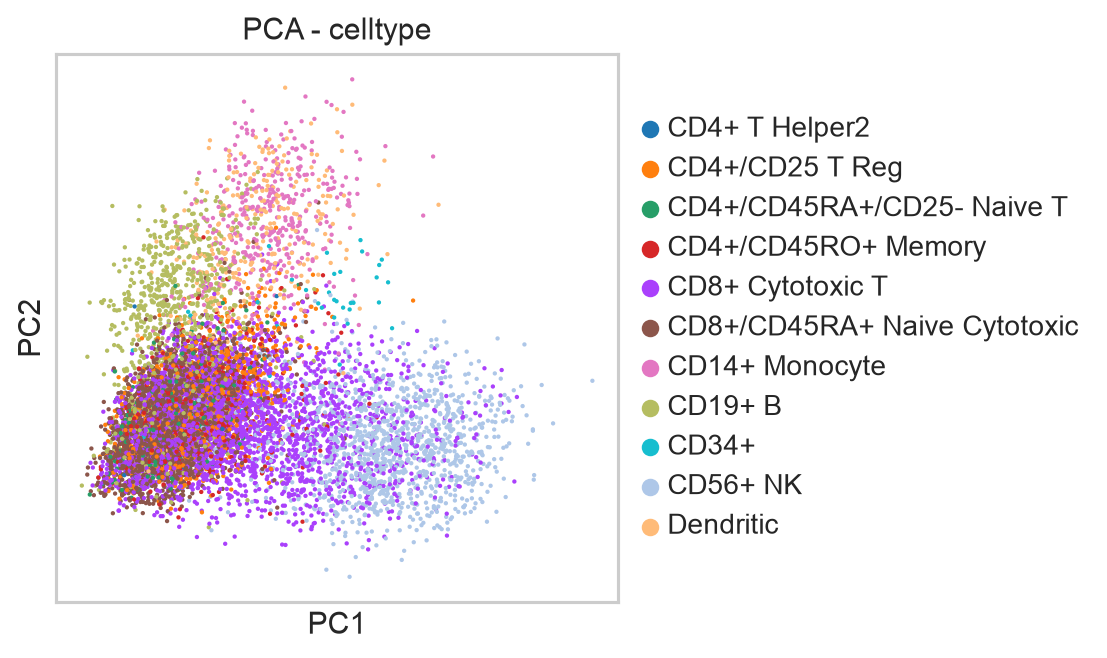

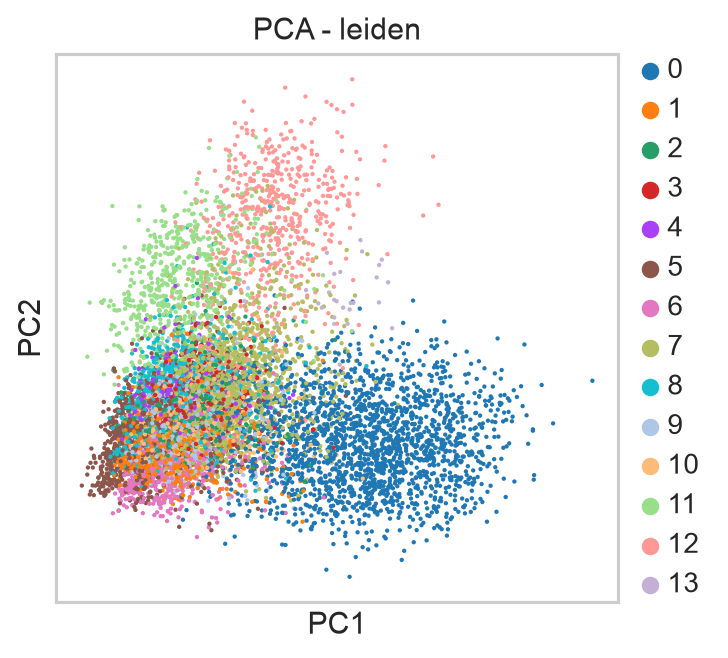

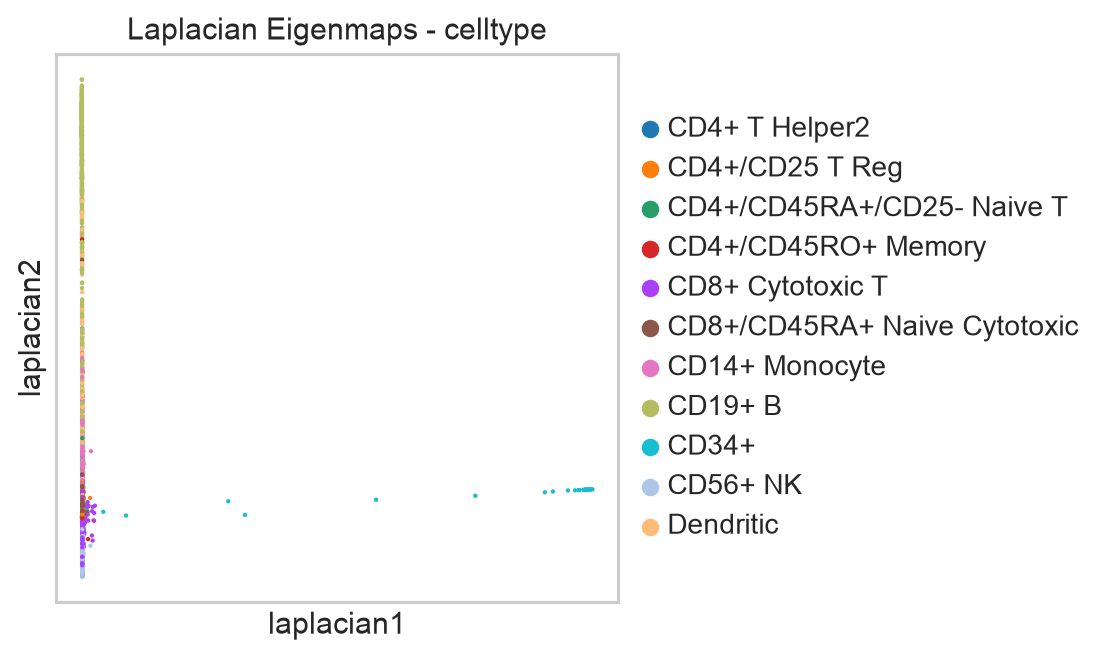

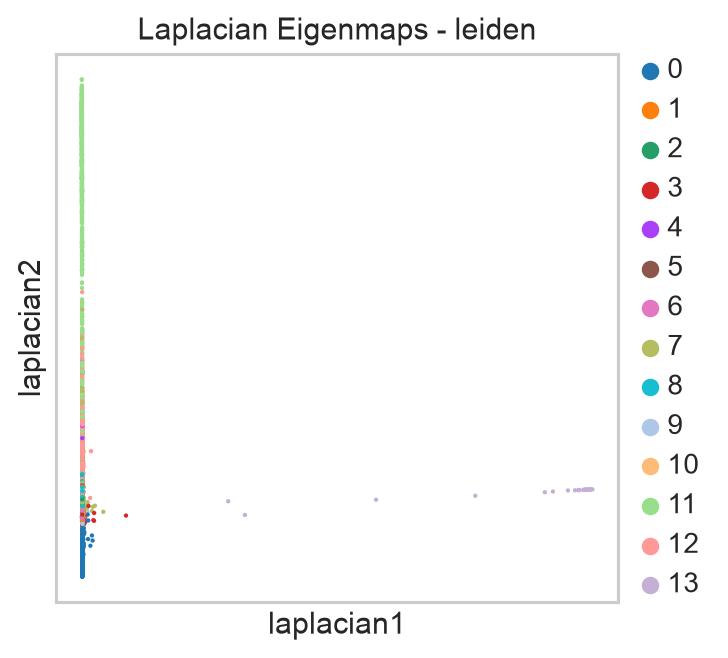

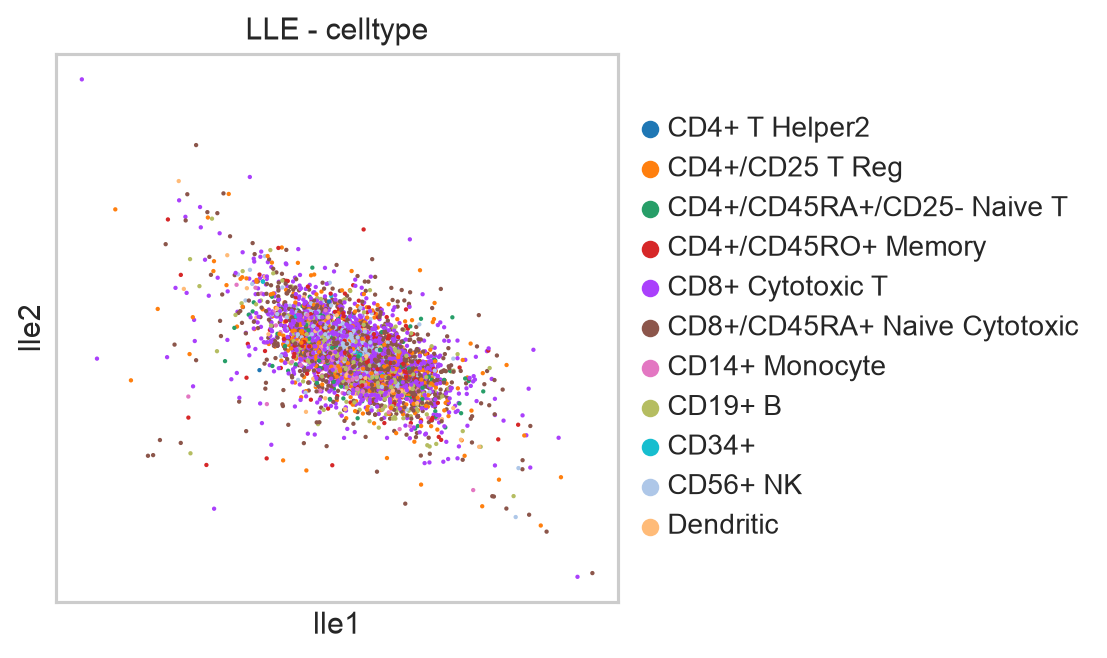

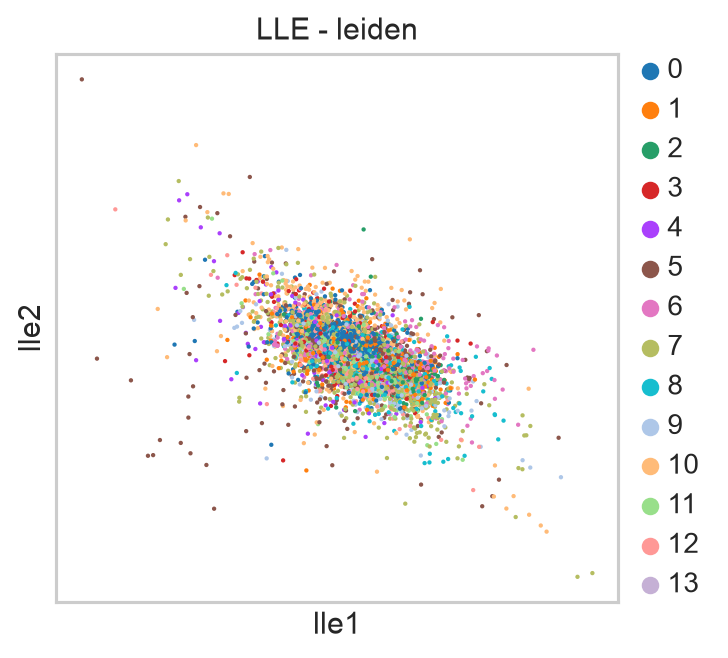

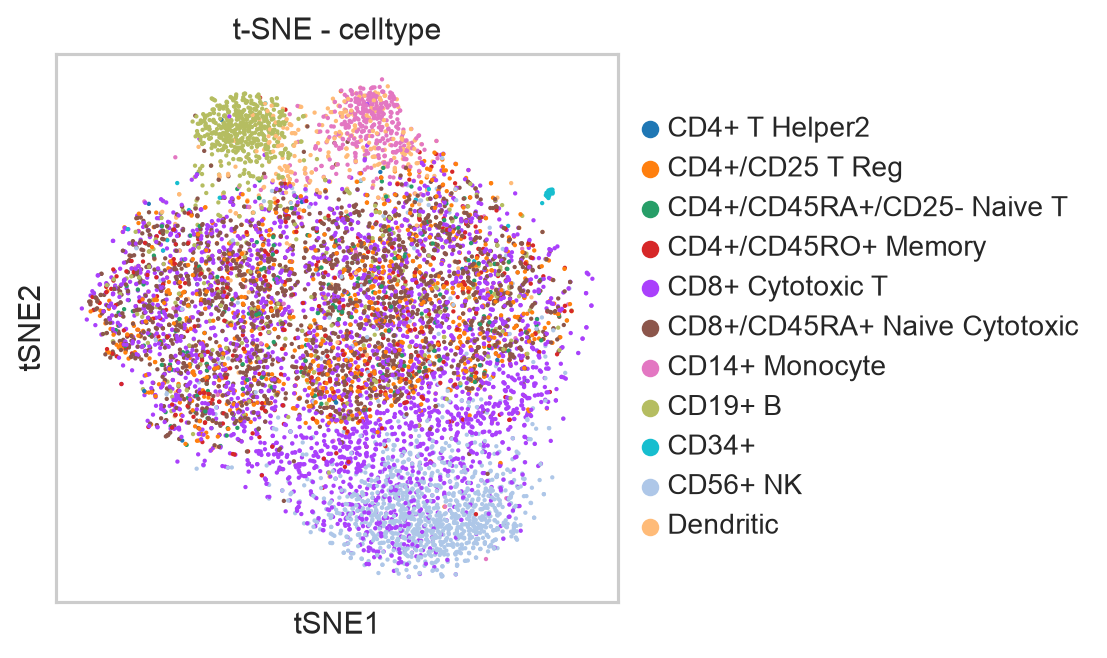

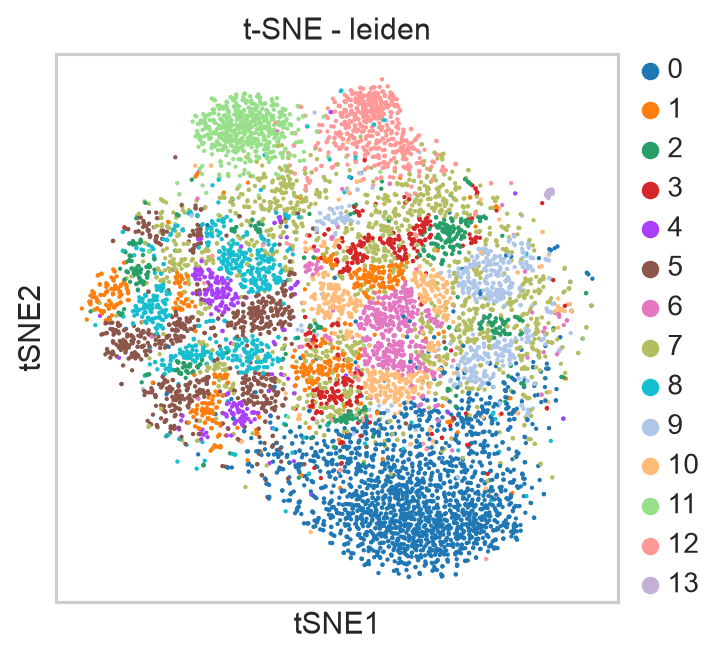

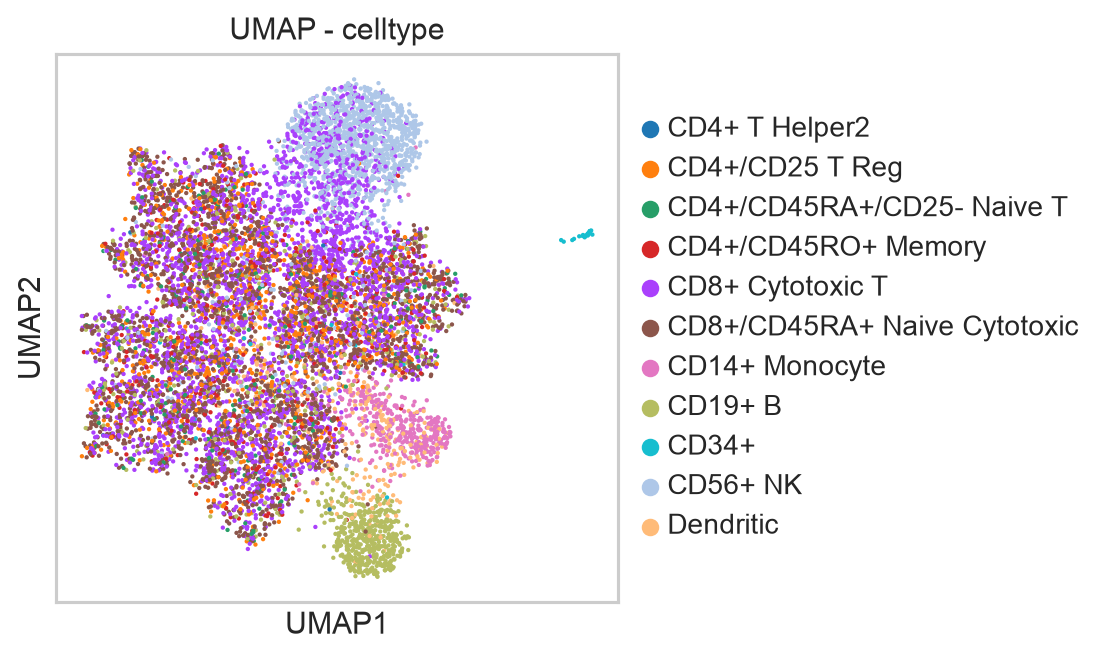

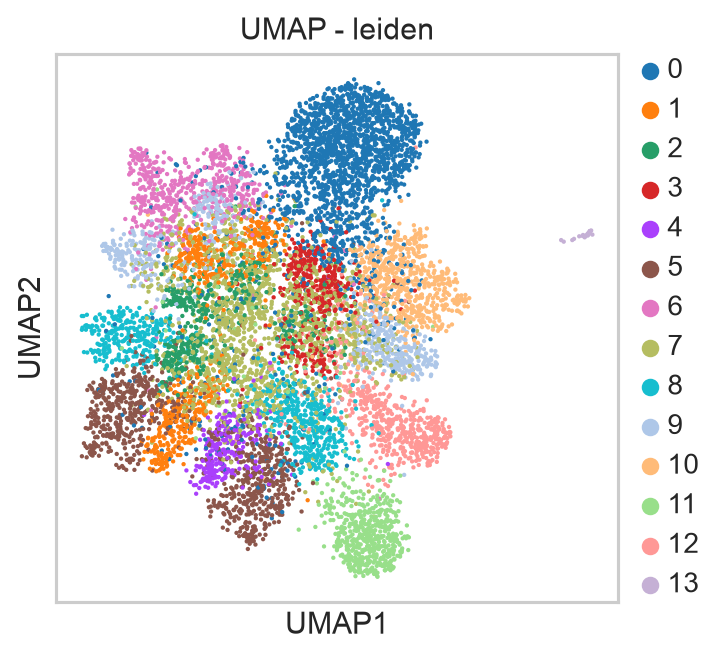

In [29]:
# Low-dimensional embeddings for VISUALIZATION ONLY, on an independent subsample (viz).
# This is fully decoupled from the full-graph homophily/split above: changing SUBSAMPLE
# only affects these plots, never the homophily numbers or the model split.
import time

if SUBSAMPLE is not None and work.n_obs > SUBSAMPLE:
    from sklearn.model_selection import train_test_split as _tts
    _vidx, _ = _tts(np.arange(work.n_obs), train_size=SUBSAMPLE,
                    stratify=work.obs[LABEL_COL].to_numpy(), random_state=SEED)
    viz = work[np.sort(_vidx)].copy()
    print(f"Embedding subsample: {viz.n_obs:,}/{work.n_obs:,} cells")
else:
    viz = work
    print(f"Embeddings on all {viz.n_obs:,} cells")

# viz needs its own PCA + neighbor graph (the full-graph ones live on `work`).
sc.pp.pca(viz, n_comps=N_PCS, svd_solver="arpack", random_state=SEED)
sc.pp.neighbors(viz, n_neighbors=15, n_pcs=N_PCS_USE, use_rep="X_pca", random_state=SEED)
Pv = np.asarray(viz.obsm["X_pca"][:, :N_PCS_USE], dtype=np.float64)
if "leiden" in work.obs:  # carry Leiden labels onto the subsample for coloring
    viz.obs["leiden"] = work.obs["leiden"].reindex(viz.obs_names).values

start = time.time()
viz.obsm["X_laplacian"] = SpectralEmbedding(
    n_components=2, affinity="nearest_neighbors", n_neighbors=15, random_state=SEED
).fit_transform(Pv)
print(f"Laplacian time taken {time.time()-start:.1f}s")

start = time.time()
viz.obsm["X_lle"] = LocallyLinearEmbedding(
    n_components=2, n_neighbors=15, method="standard", random_state=SEED
).fit_transform(Pv)
print(f"LLE time taken {time.time()-start:.1f}s")

start = time.time()
sc.tl.tsne(viz, use_rep="X_pca", n_pcs=N_PCS_USE, random_state=SEED, n_jobs=-1)
print(f"tSNE time taken {time.time()-start:.1f}s")

start = time.time()
sc.tl.umap(viz, random_state=SEED)
print(f"UMAP time taken {time.time()-start:.1f}s")

embeddings = [
    ("X_pca", "PCA"),
    ("X_laplacian", "Laplacian Eigenmaps"),
    ("X_lle", "LLE"),
    ("X_tsne", "t-SNE"),
    ("X_umap", "UMAP"),
]
for key, title in embeddings:
    plot_embedding(viz, key, title, color=("celltype", "leiden"))


#### Existing metadata against the embedding
Plot categorical columns with at most 25 levels, if any exist. These columns come from the file; the notebook does not import labels. A clear separation may reflect biology or technical effects and needs interpretation in context.

In [30]:
# candidate_columns = [c for c in adata.obs.columns
#                      if 2 <= adata.obs[c].nunique(dropna=True) <= 25
#                      and (pd.api.types.is_categorical_dtype(adata.obs[c]) or
#                           pd.api.types.is_object_dtype(adata.obs[c]) or
#                           pd.api.types.is_string_dtype(adata.obs[c]))]
# print("Eligible existing categorical columns:", candidate_columns)
# for column in candidate_columns[:8]:
#     sc.pl.umap(work, color=column, title=f"File metadata: {column}", show=True)
# if len(candidate_columns) > 8:
#     print("Showing first eight columns; inspect candidate_columns for others.")


## Part 10 — Persist processed artifacts
*Contribution: the clean hand-off from Step 1 to Steps 2–4 — collaborators load the representation, graph, features and split in one line instead of rerunning the pipeline.*

Save `work` and the GNN-ready side files to `data/processed` (git-ignored). `work_processed.h5ad` is the complete object; `X_pca.npy` and `X_features.npy` (node features) with `feature_blocks.json` (block→column map), `connectivities.npz` (kNN graph), and `cell_metadata.csv` (labels, masks, local homophily) serve PyG/sklearn users who don't use scanpy.

In [31]:
# ============================================================
# Section 6 — Persist processed artifacts
# Save key outputs so collaborators can skip the whole pipeline.
# Files go to data/processed (git-ignored). .h5ad is the complete source of truth;
# the .npy/.npz/.csv side files serve PyG / sklearn users who don't use scanpy.
# ============================================================
import os, json, scipy.sparse as sp

os.makedirs("data/processed", exist_ok=True)

# 1) Complete AnnData (X, obsm incl. X_features, obsp graph, obs, var, uns) — one-line reload.
work.write_h5ad("data/processed/work_processed.h5ad", compression="gzip")

# 2) GNN side files (no scanpy needed):
#    - PCA node features P (n_cells x 30)
np.save("data/processed/X_pca.npy", work.obsm["X_pca"])
#    - augmented node features + the block->column map (for ablations & attribution)
if "X_features" in work.obsm:
    np.save("data/processed/X_features.npy", work.obsm["X_features"])
    json.dump(work.uns.get("feature_blocks", {}), open("data/processed/feature_blocks.json", "w"), indent=2)
#    - kNN graph as a sparse adjacency matrix -> trivially -> PyG edge_index
sp.save_npz("data/processed/connectivities.npz", work.obsp["connectivities"].tocsr())
#    - labels + masks + metadata (small, human-readable table)
meta_cols = ["celltype", "celltype_coarse", "leiden", "local_homophily",
             "train_mask", "val_mask", "test_mask"]
meta_cols = [c for c in meta_cols if c in work.obs.columns]
work.obs[meta_cols].to_csv("data/processed/cell_metadata.csv")

# Confirm what was written + sizes
for f in ["work_processed.h5ad", "X_pca.npy", "X_features.npy", "feature_blocks.json",
          "connectivities.npz", "cell_metadata.csv"]:
    p = os.path.join("data/processed", f)
    if os.path.exists(p):
        print(f"  wrote data/processed/{f:22s} {os.path.getsize(p)/1e6:8.2f} MB")


  wrote data/processed/work_processed.h5ad      115.79 MB
  wrote data/processed/X_pca.npy                 13.12 MB
  wrote data/processed/X_features.npy            43.54 MB
  wrote data/processed/feature_blocks.json        0.00 MB
  wrote data/processed/connectivities.npz         9.42 MB
  wrote data/processed/cell_metadata.csv          4.92 MB


In [32]:
# --- How teammates reload (no need to rerun the pipeline) ---
# import anndata as ad
# work = ad.read_h5ad("data/work_processed.h5ad")      # full object
# import numpy as np, scipy.sparse as sp, pandas as pd
# X   = np.load("data/X_pca.npy")                       # node features (n x 50)
# A   = sp.load_npz("data/connectivities.npz")          # kNN adjacency (sparse)
# meta= pd.read_csv("data/cell_metadata.csv", index_col=0)  # labels + masks